# 02 — So sánh 7 mô hình tối ưu hóa danh mục trên VN30 (7 nhóm ngành)

**Đồ án Tối ưu hóa & Ứng dụng — UIT**  ·  Dữ liệu: `data/processed/VN30_Sectors_Returns_clean.csv` (tạo bởi `01_EDA.ipynb`)

| # | Mô hình | Lớp bài toán tối ưu | Thuật toán giải | Dùng $\mu$? | Thước đo rủi ro |
|---|---|---|---|---|---|
| 1 | **Markowitz** (Max Sharpe) | Quy hoạch toàn phương (QP) lồi sau phép đổi biến | SLSQP | Có | Phương sai |
| 2 | **NSGA-III** | Đa mục tiêu (3 mục tiêu), không lồi | Tiến hóa, reference directions | Có | Volatility + Max Drawdown |
| 3 | **MAP-Elites** (Grid) | Quality-Diversity | Tiến hóa, lưu trữ dạng lưới | Có | (fitness: Sharpe) |
| 4 | **CVT-MAP-Elites** | Quality-Diversity | Tiến hóa, lưu trữ Voronoi (k-means) | Có | (fitness: Sharpe) |
| 5 | **Mean-CVaR** (Max STARR) | Quy hoạch tuyến tính (LP) | HiGHS (simplex/IPM) | Có | CVaR 95% |
| 6 | **HRP** | Heuristic phân cấp (không giải bài toán tối ưu) | Phân cụm + chia đôi đệ quy | **Không** | Phương sai cụm |
| 7 | **Black-Litterman** | QP trên tham số hậu nghiệm Bayes | SLSQP | Có (co về prior) | Phương sai |

Hai danh mục tham chiếu: **1/N (7 ngành)** và **VN30-EW** (tỷ trọng ngành theo số mã trong VN30).

### Thiết kế thực nghiệm
- **Phần A — In-sample (toàn mẫu)**: hiểu hành vi từng thuật toán: nghiệm, đường biên, hội tụ, chất lượng nghiệm của thuật toán tiến hóa so với nghiệm tối ưu chính xác, độ ổn định theo seed và theo nhiễu dữ liệu. *Không dùng để kết luận hiệu quả đầu tư* (vì có look-ahead).
- **Phần B — Out-of-sample (walk-forward)**: tại mỗi lần tái cân bằng, chỉ dùng **2 năm dữ liệu quá khứ** để ước lượng → nắm giữ 21 phiên (~1 tháng) → lặp lại. Có tính phí giao dịch. Đây là căn cứ chính để so sánh.

### Mô hình toán học

**1. Markowitz — Max Sharpe.** $\max_w \dfrac{\mu^\top w - r_f}{\sqrt{w^\top\Sigma w}}$ s.t. $\mathbf 1^\top w = 1,\ w\ge 0$. Hàm mục tiêu phân thức không lồi; đặt $y = w/\big((\mu-r_f)^\top w\big)$ ta được QP lồi:
$$\min_y\ y^\top\Sigma y \quad\text{s.t.}\quad (\mu - r_f\mathbf 1)^\top y = 1,\ y\ge 0,\qquad w^* = y^*/\mathbf 1^\top y^*.$$

**2. NSGA-III.** $\min_w \big(-\mu^\top w,\ \sqrt{w^\top\Sigma w},\ \mathrm{MDD}(w)\big)$ trên simplex. $\mathrm{MDD}(w)=\max_t\big(1 - V_t/\max_{s\le t}V_s\big)$ phụ thuộc đường đi, không lồi, không khả vi → không giải được bằng QP/LP, phù hợp với thuật toán tiến hóa. Chọn nghiệm cuối từ tập Pareto bằng quy tắc **max Calmar** = $\mu^\top w/\mathrm{MDD}(w)$.

**3–4. MAP-Elites / CVT-MAP-Elites.** Fitness $f(w)$ = Sharpe; behavior descriptor $b(w) = \big(\sigma(w),\ \mathrm{ENB}(w)\big)$, với $\mathrm{ENB} = 1/\sum_i w_i^2$ (số "tài sản hiệu dụng", từ 1 đến 7). Mỗi ô (Grid 20×20) hoặc mỗi niche Voronoi (CVT, 200 centroid) giữ nghiệm có fitness tốt nhất. Toán tử biến dị Iso+LineDD: $w' = w_1 + \sigma_{iso}\,\mathcal N(0,I) + \sigma_{line}\,\mathcal N(0,1)(w_2-w_1)$, rồi chiếu lên simplex. Chọn nghiệm cuối: elite có Sharpe cao nhất **trong số các danh mục có ENB ≥ 3** (ràng buộc đa dạng hóa áp dụng *sau khi* tối ưu, đây là lợi thế của Quality-Diversity).

**5. Mean-CVaR (Rockafellar–Uryasev).** Với $T$ kịch bản lịch sử $r_s$:
$$\mathrm{CVaR}_\beta(w) = \min_\alpha\ \alpha + \frac{1}{(1-\beta)T}\sum_{s=1}^T \big[-r_s^\top w - \alpha\big]^+$$
Max STARR $=\max (\mu^\top w - r_f)/\mathrm{CVaR}_\beta(w)$, tuyến tính hóa bằng phép biến đổi **Charnes–Cooper** ($y = t\,w$):
$$\min_{y,\alpha,u,t}\ \alpha + \tfrac{1}{(1-\beta)T}\textstyle\sum_s u_s\quad\text{s.t.}\ u_s \ge -r_s^\top y - \alpha,\ u\ge 0,\ (\mu-r_f)^\top y = 1,\ \mathbf 1^\top y = t,\ y\ge 0.$$

**6. HRP (López de Prado 2016).** (i) Phân cụm phân cấp với khoảng cách $d_{ij}=\sqrt{(1-\rho_{ij})/2}$; (ii) sắp xếp lại ma trận theo thứ tự lá (quasi-diagonalization); (iii) chia đôi đệ quy, phân bổ $\alpha = 1 - \frac{V_L}{V_L+V_R}$ cho nhánh trái, với $V$ là phương sai của danh mục inverse-variance trong cụm.

**7. Black-Litterman.** Prior $\pi = \delta\Sigma w_{mkt}$ ($\delta = 2.5$, $w_{mkt}$ = tỷ trọng số mã/30). Views momentum tương đối $P\mu = Q + \varepsilon$, $\Omega = \mathrm{diag}(\tau P\Sigma P^\top)$, $\tau = 0.05$:
$$\mu_{BL} = \big[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\big]^{-1}\big[(\tau\Sigma)^{-1}\pi + P^\top\Omega^{-1}Q\big],\qquad \Sigma_{BL} = \Sigma + \big[(\tau\Sigma)^{-1} + P^\top\Omega^{-1}P\big]^{-1}$$
rồi giải $\max_w\ w^\top\mu_{BL} - \tfrac{\delta}{2}w^\top\Sigma_{BL}w$ (long-only).

## 0. Thiết lập

In [1]:
%matplotlib inline
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

from scripts import data_utils as du, metrics as M, viz, backtest as bt
from scripts import markowitz as mk, nsga3, map_elites as me, mean_cvar as mc, hrp, black_litterman as bl

warnings.filterwarnings("ignore", category=RuntimeWarning)
viz.set_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# ---------------- Tham số thực nghiệm ----------------
RF        = 0.03    # lãi suất phi rủi ro năm
BETA      = 0.95    # mức tin cậy CVaR
LOOKBACK  = 484     # cửa sổ ước lượng = 2 năm (~242 phiên/năm)
REBAL     = 21      # tái cân bằng mỗi 21 phiên (~1 tháng)
COST_BPS  = 20      # phí giao dịch 0.20% trên giá trị giao dịch (phí môi giới + thuế bán)
MIN_ENB   = 3.0     # ràng buộc đa dạng hóa khi chọn elite MAP-Elites
SEED      = 42
# Ngân sách đánh giá bằng nhau cho các thuật toán tiến hóa (~26.6k lượt)
NSGA_KW = dict(objectives=("return", "volatility", "mdd"), n_partitions=12, n_gen=289)   # 92 cá thể x 289 thế hệ
ME_KW   = dict(n_init=1000, n_iter=200, batch=128, bins_per_dim=20, n_niches=200)

sec = du.load_clean("sector")
SECTORS = list(sec.columns)
VI = du.SECTOR_VI
LAB = [VI[s] for s in SECTORS]
SEC_COLORS = dict(zip(SECTORS, viz.CATEGORICAL))
PPY = du.periods_per_year(sec.index)
RF_D = M.rf_per_period(RF, PPY)
mapping = du.load_raw()["mapping"]
W_MKT = (du.sector_counts(mapping) / 30).reindex(SECTORS).to_numpy()

print(f"{len(sec)} phiên | {sec.index[0].date()} -> {sec.index[-1].date()} | {PPY:.1f} phiên/năm | N = {len(SECTORS)} ngành")
print("w_mkt (VN30-EW theo ngành):", dict(zip(LAB, W_MKT.round(3))))

1206 phiên | 2021-10-15 -> 2026-10-09 | 242.0 phiên/năm | N = 7 ngành
w_mkt (VN30-EW theo ngành): {'Ngân hàng': np.float64(0.433), 'Bất động sản': np.float64(0.133), 'Tiêu dùng & Bán lẻ': np.float64(0.133), 'Năng lượng & Tiện ích': np.float64(0.1), 'Thép & Vật liệu': np.float64(0.067), 'Công nghệ': np.float64(0.033), 'Dịch vụ tài chính': np.float64(0.1)}


Các hàm chiến lược dưới đây nhận **một cửa sổ dữ liệu quá khứ** và trả về vector tỷ trọng. Chúng được dùng chung cho Phần A (cửa sổ = toàn mẫu) và Phần B (cửa sổ trượt). Kết quả của các thuật toán tiến hóa được cache theo nội dung cửa sổ, để các biến thể quy tắc chọn nghiệm (ablation) dùng chung một lần chạy.

In [2]:
def estimate(window):
    mu, cov = du.estimate_moments(window, PPY)
    return window.to_numpy(), mu, cov

_cache = {}
def cached(tag, window, fn):
    key = (tag, hash(window.to_numpy().tobytes()))
    if key not in _cache:
        _cache[key] = fn()
    return _cache[key]

def run_nsga(window, seed=SEED):
    R, mu, cov = estimate(window)
    return cached(("nsga", seed), window, lambda: nsga3.run_nsga3(R, mu, cov, RF, seed=seed, **NSGA_KW))

def run_me(window, variant, seed=SEED):
    R, mu, cov = estimate(window)
    return cached(("me", variant, seed), window,
                  lambda: me.run_map_elites(me.Evaluator(R, mu, cov, RF), variant=variant, seed=seed, **ME_KW))

def bl_strategy(window, details=False):
    R, mu, cov = estimate(window)
    P, Q, views = bl.momentum_views(window, PPY, lookback=126, skip=21, n_pairs=2, scale=0.5)
    out = bl.black_litterman_weights(cov, W_MKT, P, Q, delta=2.5, tau=0.05, return_details=details)
    return (out, P, Q, views) if details else out

STRATEGIES = {
    "Markowitz":       lambda w: mk.max_sharpe(*estimate(w)[1:], RF),
    "NSGA-III":        lambda w: run_nsga(w).select("max_calmar"),
    "MAP-Elites":      lambda w: run_me(w, "grid").select(min_enb=MIN_ENB),
    "CVT-MAP-Elites":  lambda w: run_me(w, "cvt").select(min_enb=MIN_ENB),
    "Mean-CVaR":       lambda w: mc.max_starr(w.to_numpy(), RF_D, BETA),
    "HRP":             lambda w: hrp.hrp_weights(w.cov().to_numpy()),
    "Black-Litterman": lambda w: bl_strategy(w),
    "1/N (7 ngành)":   lambda w: np.full(w.shape[1], 1 / w.shape[1]),
    "VN30-EW":         lambda w: W_MKT.copy(),
}
MODELS = viz.MODELS
ALL = list(STRATEGIES)

---
# PHẦN A — PHÂN TÍCH IN-SAMPLE (TOÀN MẪU)

In [3]:
R, MU, COV = estimate(sec)
VOL_A = np.sqrt(np.diag(COV))

def stats_row(w):
    ret, vol, sr = mk.portfolio_stats(w, MU, COV, RF)
    return {"μ năm": ret, "σ năm": vol, "Sharpe": sr, "CVaR95 (ngày)": mc.portfolio_cvar(w, R, BETA),
            "MaxDD": M.max_drawdown(R @ w), "ENB": M.enb(w)}

def weight_table(d):
    return viz.fmt(pd.DataFrame(d, index=LAB).T, pct=LAB, pct_dec=1)

## A1. Markowitz: đường biên hiệu quả

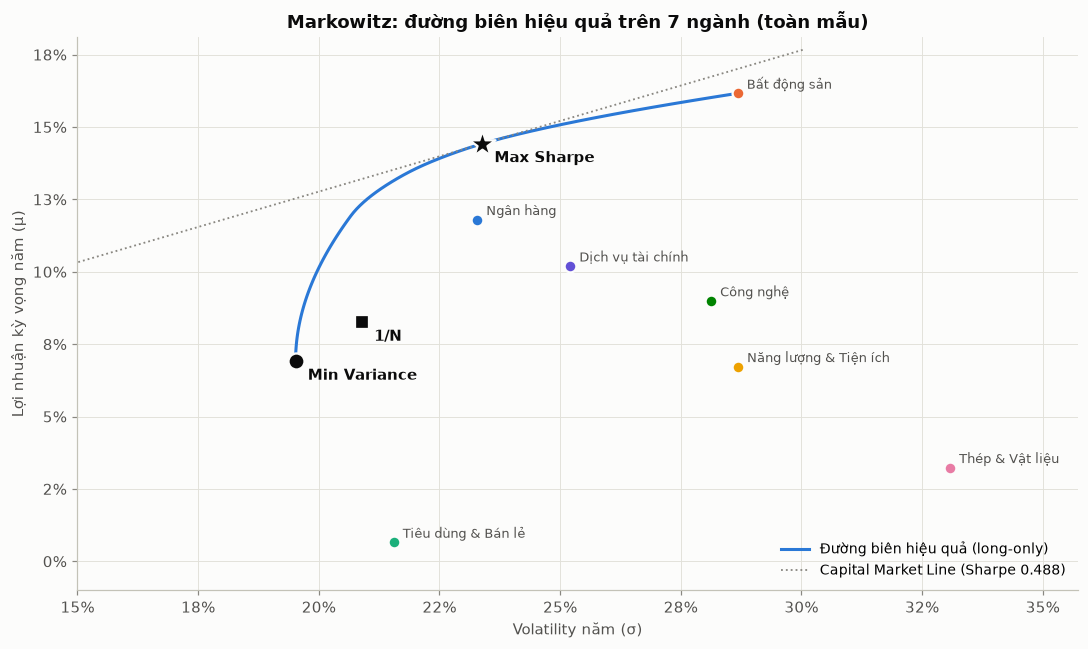

,Ngân hàng,Bất động sản,Tiêu dùng & Bán lẻ,Năng lượng & Tiện ích,Thép & Vật liệu,Công nghệ,Dịch vụ tài chính
Max Sharpe,39.9%,60.1%,0.0%,0.0%,0.0%,0.0%,0.0%
Min Variance,21.6%,12.7%,40.5%,11.3%,0.0%,11.0%,2.9%


,μ năm,σ năm,Sharpe,CVaR95 (ngày),MaxDD,ENB
Max Sharpe,14.42%,23.39%,0.488,3.81%,34.90%,1.922
Min Variance,6.90%,19.52%,0.200,3.26%,27.94%,3.954
1/N,8.25%,20.90%,0.251,3.53%,38.32%,7.000


Thời gian giải Max Sharpe (QP): 1.1 ms


In [4]:
t0 = time.perf_counter()
w_ms = mk.max_sharpe(MU, COV, RF)
t_mk = time.perf_counter() - t0
w_mv = mk.min_variance(COV)
fr_vol, fr_ret, fr_W = mk.efficient_frontier(MU, COV, n_points=80)
w_eq = np.full(7, 1 / 7)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(fr_vol, fr_ret, color=viz.color("Markowitz"), lw=2, label="Đường biên hiệu quả (long-only)")
sr_ms = (w_ms @ MU - RF) / np.sqrt(w_ms @ COV @ w_ms)
xs = np.linspace(0, fr_vol.max() * 1.05, 20)
ax.plot(xs, RF + sr_ms * xs, color=viz.MUTED, ls=":", lw=1.2, label=f"Capital Market Line (Sharpe {sr_ms:.3f})")
for s, v, m in zip(SECTORS, VOL_A, MU):
    ax.scatter(v, m, s=60, color=SEC_COLORS[s], edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(VI[s], (v, m), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=viz.INK2)
pts = {"Max Sharpe": (w_ms, "*", 320), "Min Variance": (w_mv, "o", 110), "1/N": (w_eq, "s", 90)}
for name, (w, mkr, size) in pts.items():
    r_, v_, _ = mk.portfolio_stats(w, MU, COV, RF)
    ax.scatter(v_, r_, marker=mkr, s=size, color=viz.INK, edgecolor=viz.SURFACE, linewidth=1.5, zorder=5)
    ax.annotate(name, (v_, r_), xytext=(8, -12), textcoords="offset points", fontsize=9.5, fontweight="bold", color=viz.INK)
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.set_xlim(0.15, VOL_A.max() * 1.08); ax.set_ylim(-0.01, MU.max() * 1.12)
ax.set_xlabel("Volatility năm (σ)"); ax.set_ylabel("Lợi nhuận kỳ vọng năm (μ)")
ax.set_title("Markowitz: đường biên hiệu quả trên 7 ngành (toàn mẫu)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

display(weight_table({"Max Sharpe": w_ms, "Min Variance": w_mv}))
display(viz.fmt(pd.DataFrame({"Max Sharpe": stats_row(w_ms), "Min Variance": stats_row(w_mv), "1/N": stats_row(w_eq)}).T,
                pct=("μ năm", "σ năm", "CVaR95 (ngày)", "MaxDD")))
print(f"Thời gian giải Max Sharpe (QP): {t_mk*1000:.1f} ms")

Nghiệm Max Sharpe **tập trung cao** vào 2 ngành có $\hat\mu$ lớn nhất trong mẫu, là hành vi "góc" (corner solution) điển hình của Markowitz long-only. Theo EDA mục 11, $\hat\mu$ của cả hai ngành đều có khoảng tin cậy chứa 0, nên đây là một nghiệm *tối ưu theo số liệu* nhưng *rất dễ vỡ* ngoài mẫu.

## A2. NSGA-III: tập Pareto 3 mục tiêu (lợi nhuận, volatility, max drawdown)

NSGA-III: 48 nghiệm không bị trội | 26,588 lượt đánh giá | 2.45 s


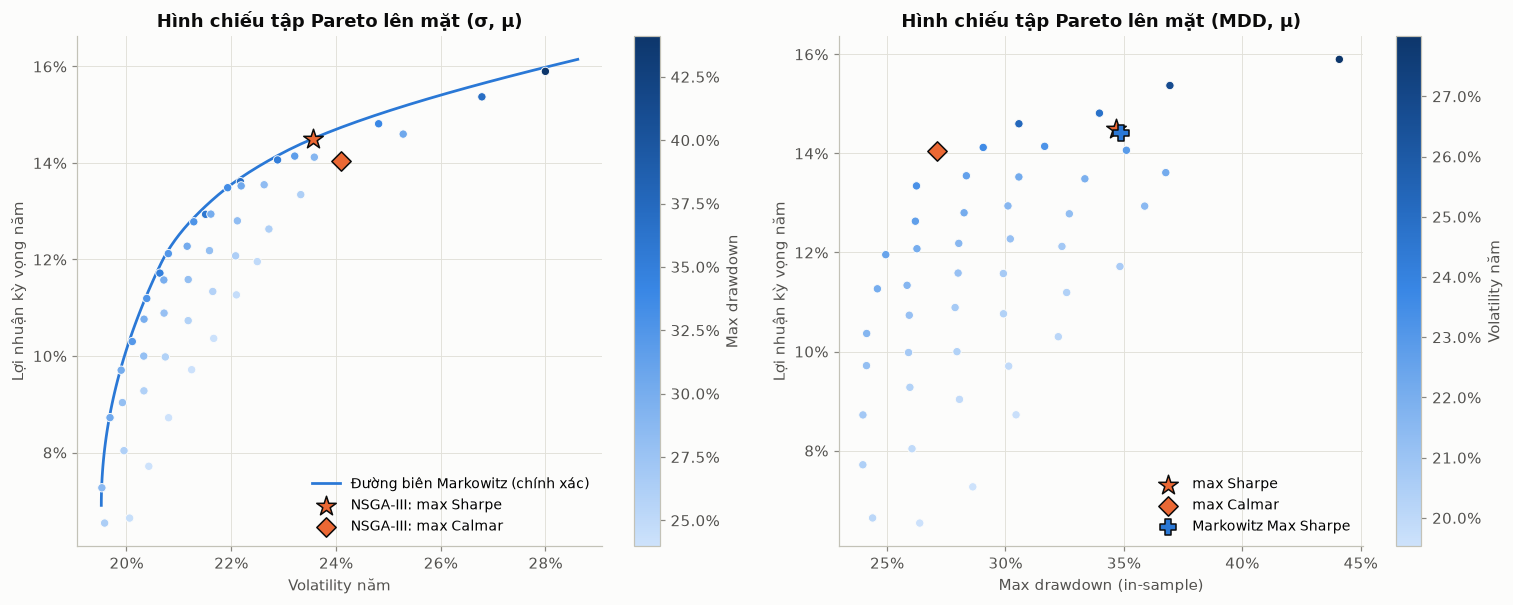

,Ngân hàng,Bất động sản,Tiêu dùng & Bán lẻ,Năng lượng & Tiện ích,Thép & Vật liệu,Công nghệ,Dịch vụ tài chính
NSGA-III max Sharpe,37.9%,62.0%,0.0%,0.0%,0.0%,0.0%,0.0%
NSGA-III max Calmar,4.7%,69.2%,0.0%,1.7%,0.0%,24.4%,0.0%
Markowitz Max Sharpe,39.9%,60.1%,0.0%,0.0%,0.0%,0.0%,0.0%


,μ năm,σ năm,Sharpe,CVaR95 (ngày),MaxDD,ENB
NSGA-III max Sharpe,14.50%,23.56%,0.488,3.82%,34.66%,1.894
NSGA-III max Calmar,14.05%,24.10%,0.458,3.79%,27.11%,1.851
Markowitz Max Sharpe,14.42%,23.39%,0.488,3.81%,34.90%,1.922


In [5]:
t0 = time.perf_counter()
res_ns = nsga3.run_nsga3(R, MU, COV, RF, seed=SEED, track_history=True, **NSGA_KW)
t_ns = time.perf_counter() - t0
w_ns_sharpe, w_ns_calmar = res_ns.select("max_sharpe"), res_ns.select("max_calmar")
F = res_ns.F  # cột: return, volatility, mdd
print(f"NSGA-III: {len(res_ns.W)} nghiệm không bị trội | {res_ns.n_eval:,} lượt đánh giá | {t_ns:.2f} s")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
ax = axes[0]
sc = ax.scatter(F[:, 1], F[:, 0], c=F[:, 2], cmap=viz.SEQUENTIAL, s=30, edgecolor=viz.SURFACE, linewidth=0.6, zorder=3)
ax.plot(fr_vol, fr_ret, color=viz.color("Markowitz"), lw=1.8, label="Đường biên Markowitz (chính xác)")
for w, mkr, lab in [(w_ns_sharpe, "*", "NSGA-III: max Sharpe"), (w_ns_calmar, "D", "NSGA-III: max Calmar")]:
    r_, v_, _ = mk.portfolio_stats(w, MU, COV, RF)
    ax.scatter(v_, r_, marker=mkr, s=180 if mkr == "*" else 80, color=viz.color("NSGA-III"), edgecolor=viz.INK, linewidth=1, zorder=5, label=lab)
plt.colorbar(sc, ax=ax, format=plt.matplotlib.ticker.PercentFormatter(1.0)).set_label("Max drawdown")
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.set_xlabel("Volatility năm"); ax.set_ylabel("Lợi nhuận kỳ vọng năm")
ax.set_title("Hình chiếu tập Pareto lên mặt (σ, μ)"); ax.legend(loc="lower right")

ax = axes[1]
sc = ax.scatter(F[:, 2], F[:, 0], c=F[:, 1], cmap=viz.SEQUENTIAL, s=30, edgecolor=viz.SURFACE, linewidth=0.6, zorder=3)
for w, mkr, lab in [(w_ns_sharpe, "*", "max Sharpe"), (w_ns_calmar, "D", "max Calmar")]:
    ax.scatter(M.max_drawdown(R @ w), w @ MU, marker=mkr, s=180 if mkr == "*" else 80, color=viz.color("NSGA-III"),
               edgecolor=viz.INK, linewidth=1, zorder=5, label=lab)
r_, mdd_ = w_ms @ MU, M.max_drawdown(R @ w_ms)
ax.scatter(mdd_, r_, marker="P", s=120, color=viz.color("Markowitz"), edgecolor=viz.INK, linewidth=1, zorder=5, label="Markowitz Max Sharpe")
plt.colorbar(sc, ax=ax, format=plt.matplotlib.ticker.PercentFormatter(1.0)).set_label("Volatility năm")
viz.pct_axis(ax, "x"); viz.pct_axis(ax, "y")
ax.xaxis.set_major_locator(plt.MultipleLocator(0.05)); ax.set_xlabel("Max drawdown (in-sample)"); ax.set_ylabel("Lợi nhuận kỳ vọng năm")
ax.set_title("Hình chiếu tập Pareto lên mặt (MDD, μ)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

display(weight_table({"NSGA-III max Sharpe": w_ns_sharpe, "NSGA-III max Calmar": w_ns_calmar, "Markowitz Max Sharpe": w_ms}))
display(viz.fmt(pd.DataFrame({"NSGA-III max Sharpe": stats_row(w_ns_sharpe), "NSGA-III max Calmar": stats_row(w_ns_calmar),
                              "Markowitz Max Sharpe": stats_row(w_ms)}).T, pct=("μ năm", "σ năm", "CVaR95 (ngày)", "MaxDD")))

**Hội tụ của NSGA-III.** Ta đo hai chỉ số theo từng thế hệ: (i) **Sharpe tốt nhất** trong tập không bị trội so với nghiệm tối ưu chính xác (QP), và (ii) **hypervolume** của hình chiếu tập nghiệm lên mặt $(\sigma, -\mu)$, chuẩn hóa theo hypervolume của đường biên chính xác (= 100%).

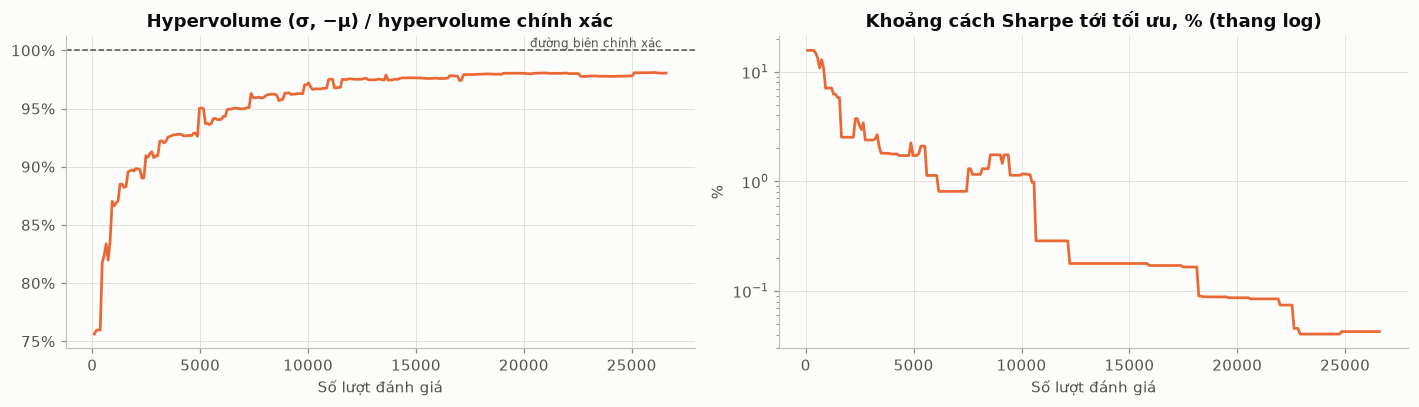

Cuối cùng: HV = 98.05% của đường biên chính xác | Sharpe gap = 0.043%


In [6]:
ref = np.array([VOL_A.max() * 1.05, -(MU.min() - 0.01)])
hv_exact = M.hypervolume_2d(np.column_stack([fr_vol, -fr_ret]), ref)
sr_star = sr_ms
gens, hv_rel, best_sr = [], [], []
for g, Wg in enumerate(res_ns.history, start=1):
    rg, vg = Wg @ MU, np.sqrt(np.einsum("ij,jk,ik->i", Wg, COV, Wg))
    gens.append(g); hv_rel.append(M.hypervolume_2d(np.column_stack([vg, -rg]), ref) / hv_exact)
    best_sr.append(((rg - RF) / vg).max())
pop = int(np.ceil(len(nsga3.get_reference_directions("das-dennis", 3, n_partitions=12)) / 4) * 4)
evals = np.array(gens) * pop

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(evals, hv_rel, color=viz.color("NSGA-III"), lw=1.8)
axes[0].axhline(1, color=viz.INK2, ls="--", lw=1); axes[0].text(evals[-1], 1.0, "đường biên chính xác ", ha="right", va="bottom", fontsize=8, color=viz.INK2)
viz.pct_axis(axes[0]); axes[0].set_xlabel("Số lượt đánh giá"); axes[0].set_title("Hypervolume (σ, −μ) / hypervolume chính xác")
axes[1].plot(evals, 100 * (sr_star - np.array(best_sr)) / sr_star, color=viz.color("NSGA-III"), lw=1.8)
axes[1].set_yscale("log"); axes[1].set_xlabel("Số lượt đánh giá"); axes[1].set_ylabel("%")
axes[1].set_title("Khoảng cách Sharpe tới tối ưu, % (thang log)")
plt.tight_layout(); plt.show()
print(f"Cuối cùng: HV = {hv_rel[-1]:.2%} của đường biên chính xác | Sharpe gap = {(sr_star - best_sr[-1]) / sr_star:.3%}")

Hypervolume trên mặt $(\sigma,\mu)$ không đạt 100% vì NSGA-III phân bổ quần thể theo **ba** mục tiêu: một phần các reference directions dành cho đánh đổi với MDD, nên tập nghiệm không phủ dày riêng đường biên 2D. Đó là cái giá của việc tối ưu thêm một mục tiêu mà Markowitz không nhìn thấy.

## A3. MAP-Elites và CVT-MAP-Elites: bản đồ các danh mục ưu tú

In [7]:
t0 = time.perf_counter(); qd_grid = run_me(sec, "grid"); t_grid = time.perf_counter() - t0
t0 = time.perf_counter(); qd_cvt = run_me(sec, "cvt");  t_cvt = time.perf_counter() - t0
w_grid, w_cvt = qd_grid.select(min_enb=MIN_ENB), qd_cvt.select(min_enb=MIN_ENB)
w_grid_free, w_cvt_free = qd_grid.select(), qd_cvt.select()
offset = min(qd_grid.history["offset"], qd_cvt.history["offset"])

qd_tbl = pd.DataFrame({
    "MAP-Elites (Grid 20×20)": {"Số ô/niche": qd_grid.archive.n_cells, "Số ô có elite": int(qd_grid.filled.sum()),
                                "Coverage": qd_grid.coverage(), "QD-score": qd_grid.qd_score(offset),
                                "Sharpe tốt nhất": qd_grid.fitness.max(), "Lượt đánh giá": qd_grid.n_eval, "Thời gian (s)": t_grid},
    "CVT-MAP-Elites (200 niche)": {"Số ô/niche": qd_cvt.archive.n_cells, "Số ô có elite": int(qd_cvt.filled.sum()),
                                   "Coverage": qd_cvt.coverage(), "QD-score": qd_cvt.qd_score(offset),
                                   "Sharpe tốt nhất": qd_cvt.fitness.max(), "Lượt đánh giá": qd_cvt.n_eval, "Thời gian (s)": t_cvt},
}).T
display(viz.fmt(qd_tbl, pct=("Coverage",)))

,Số ô/niche,Số ô có elite,Coverage,QD-score,Sharpe tốt nhất,Lượt đánh giá,Thời gian (s)
MAP-Elites (Grid 20×20),400.000,168.000,42.00%,75.210,0.488,26608.000,0.061
CVT-MAP-Elites (200 niche),200.000,200.000,100.00%,95.958,0.488,26608.000,2.218


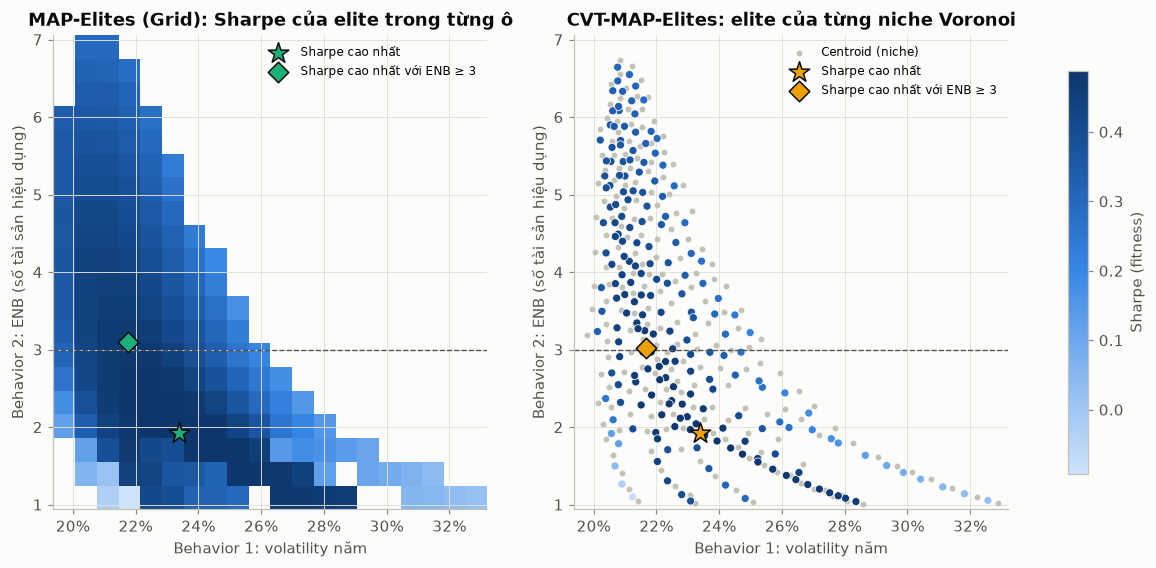

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
vmin = min(qd_grid.fitness[qd_grid.filled].min(), qd_cvt.fitness[qd_cvt.filled].min())
vmax = max(qd_grid.fitness.max(), qd_cvt.fitness.max())

ax = axes[0]
A = qd_grid.archive
Fgrid = np.where(qd_grid.filled, qd_grid.fitness, np.nan).reshape(A.bins)
im = ax.imshow(Fgrid.T, origin="lower", aspect="auto", cmap=viz.SEQUENTIAL, vmin=vmin, vmax=vmax,
               extent=[A.lo[0], A.hi[0], A.lo[1], A.hi[1]])
ax.set_title("MAP-Elites (Grid): Sharpe của elite trong từng ô")

ax = axes[1]
cent = qd_cvt.archive.cell_centers()
ax.scatter(cent[:, 0], cent[:, 1], s=8, color=viz.AXIS, zorder=1, label="Centroid (niche)")
Wc, fc, bc = qd_cvt.elites()
im = ax.scatter(bc[:, 0], bc[:, 1], c=fc, cmap=viz.SEQUENTIAL, vmin=vmin, vmax=vmax, s=28, edgecolor=viz.SURFACE, linewidth=0.5, zorder=2)
ax.set_title("CVT-MAP-Elites: elite của từng niche Voronoi")
ax.set_xlim(A.lo[0], A.hi[0]); ax.set_ylim(A.lo[1], A.hi[1])

for ax, q, col in [(axes[0], qd_grid, viz.color("MAP-Elites")), (axes[1], qd_cvt, viz.color("CVT-MAP-Elites"))]:
    for w, mkr, lab in [(q.select(), "*", "Sharpe cao nhất"), (q.select(min_enb=MIN_ENB), "D", f"Sharpe cao nhất với ENB ≥ {MIN_ENB:g}")]:
        ax.scatter(np.sqrt(w @ COV @ w), M.enb(w), marker=mkr, s=200 if mkr == "*" else 90, color=col, edgecolor=viz.INK, linewidth=1, zorder=5, label=lab)
    ax.axhline(MIN_ENB, color=viz.INK2, ls="--", lw=0.9)
    viz.pct_axis(ax, "x"); ax.set_xlabel("Behavior 1: volatility năm"); ax.set_ylabel("Behavior 2: ENB (số tài sản hiệu dụng)")
    ax.legend(loc="upper right", fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.85, label="Sharpe (fitness)")
plt.show()

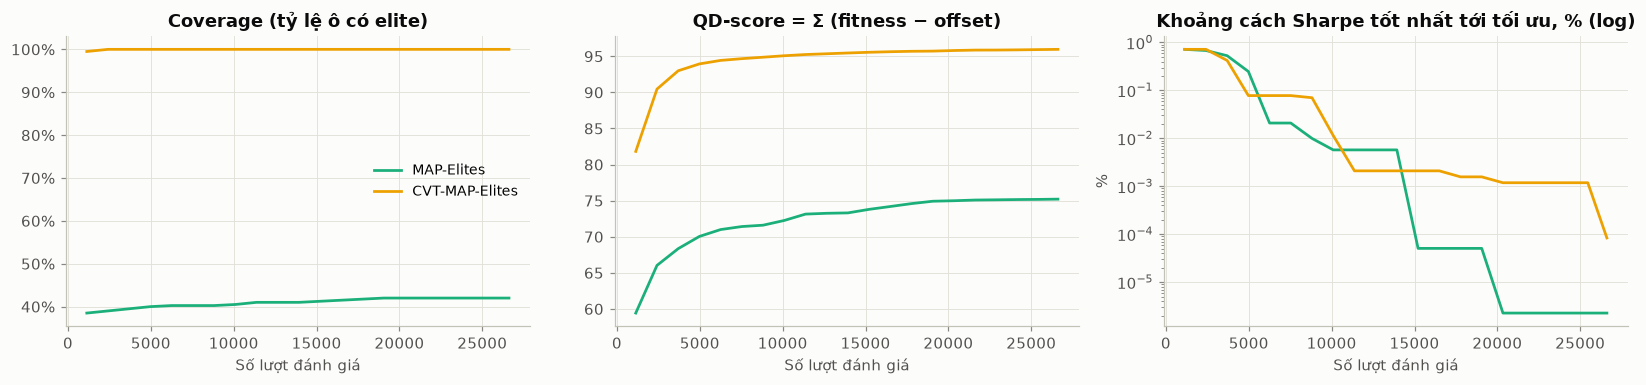

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for q, name in [(qd_grid, "MAP-Elites"), (qd_cvt, "CVT-MAP-Elites")]:
    h = q.history
    axes[0].plot(h["evals"], h["coverage"], color=viz.color(name), lw=1.8, label=name)
    axes[1].plot(h["evals"], h["qd_score"], color=viz.color(name), lw=1.8, label=name)
    axes[2].plot(h["evals"], 100 * np.maximum((sr_star - np.array(h["best"])) / sr_star, 1e-8), color=viz.color(name), lw=1.8, label=name)
axes[0].set_title("Coverage (tỷ lệ ô có elite)"); viz.pct_axis(axes[0])
axes[1].set_title("QD-score = Σ (fitness − offset)")
axes[2].set_title("Khoảng cách Sharpe tốt nhất tới tối ưu, % (log)"); axes[2].set_yscale("log"); axes[2].set_ylabel("%")
for ax in axes: ax.set_xlabel("Số lượt đánh giá")
axes[0].legend(loc="center right")
plt.tight_layout(); plt.show()

- **Grid** có 400 ô nhưng phần lớn nằm ở vùng BD **không khả thi** (vd. ENB ≈ 7 mà volatility rất cao là không thể), nên coverage thấp. Coverage của Grid và CVT không so trực tiếp được với nhau, vì CVT đặt centroid theo phân bố của danh mục khả thi.
- **CVT** giữ số niche cố định (200) bất kể số chiều BD, và hầu như mọi niche đều được lấp đầy → biểu diễn tập nghiệm hiệu quả hơn khi tăng số chiều BD.
- Cả hai đều tìm ra nghiệm **Sharpe gần như trùng** nghiệm QP chính xác (gap ~0), vì bài toán chỉ có 7 chiều.

**"Giá của đa dạng hóa".** Archive QD trả lời trực tiếp câu hỏi: *muốn danh mục đa dạng hơn (ENB cao hơn) thì phải hy sinh bao nhiêu Sharpe?* Một bộ giải single-objective chỉ trả về một điểm và không trả lời được câu hỏi này.

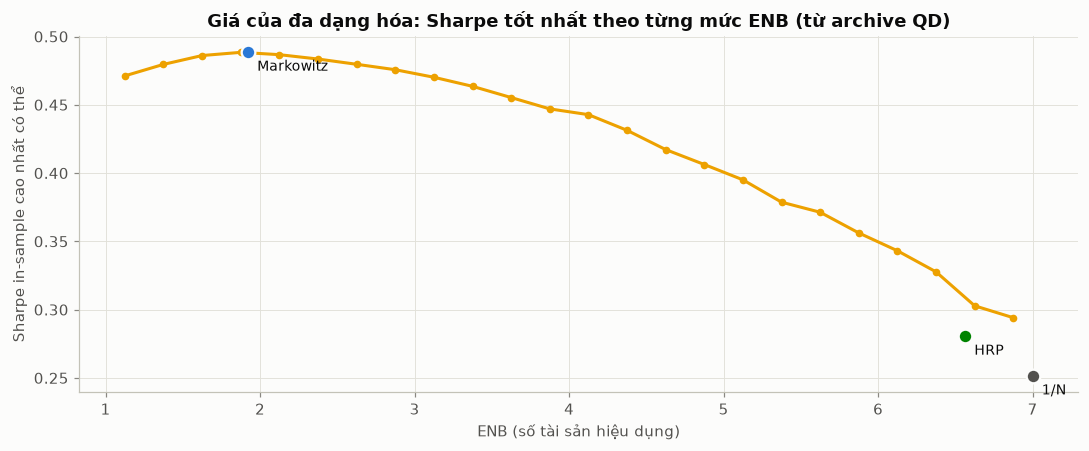

,Ngân hàng,Bất động sản,Tiêu dùng & Bán lẻ,Năng lượng & Tiện ích,Thép & Vật liệu,Công nghệ,Dịch vụ tài chính
Grid: max Sharpe,40.0%,60.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Grid: ENB≥3,31.1%,44.6%,0.1%,2.0%,0.0%,7.7%,14.6%
CVT: max Sharpe,39.8%,60.2%,0.0%,0.0%,0.0%,0.0%,0.0%
CVT: ENB≥3,35.0%,42.9%,0.0%,0.1%,0.0%,10.7%,11.2%


In [10]:
Wall = np.vstack([qd_grid.elites()[0], qd_cvt.elites()[0]])
fall = np.concatenate([qd_grid.elites()[1], qd_cvt.elites()[1]])
enb_all = 1 / (Wall ** 2).sum(1)
bins = np.arange(1, 7.01, 0.25)
best_by_enb = pd.Series([fall[(enb_all >= lo) & (enb_all < lo + 0.25)].max() if ((enb_all >= lo) & (enb_all < lo + 0.25)).any() else np.nan
                         for lo in bins[:-1]], index=bins[:-1] + 0.125)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(best_by_enb.index, best_by_enb.values, color=viz.color("CVT-MAP-Elites"), lw=2, marker="o", ms=4)
for name, w in [("Markowitz", w_ms), ("HRP", hrp.hrp_weights(COV)), ("1/N", w_eq)]:
    r_, v_, s_ = mk.portfolio_stats(w, MU, COV, RF)
    ax.scatter(M.enb(w), s_, s=80, color=viz.color(name) if name != "1/N" else viz.INK2, edgecolor=viz.SURFACE, linewidth=1.5, zorder=4)
    ax.annotate(name, (M.enb(w), s_), xytext=(6, -12), textcoords="offset points", fontsize=9, color=viz.INK)
ax.set_xlabel("ENB (số tài sản hiệu dụng)"); ax.set_ylabel("Sharpe in-sample cao nhất có thể")
ax.set_title("Giá của đa dạng hóa: Sharpe tốt nhất theo từng mức ENB (từ archive QD)")
plt.tight_layout(); plt.show()
display(weight_table({"Grid: max Sharpe": w_grid_free, f"Grid: ENB≥{MIN_ENB:g}": w_grid,
                      "CVT: max Sharpe": w_cvt_free, f"CVT: ENB≥{MIN_ENB:g}": w_cvt}))

## A4. Mean-CVaR: đường biên trong mặt phẳng (CVaR, μ)

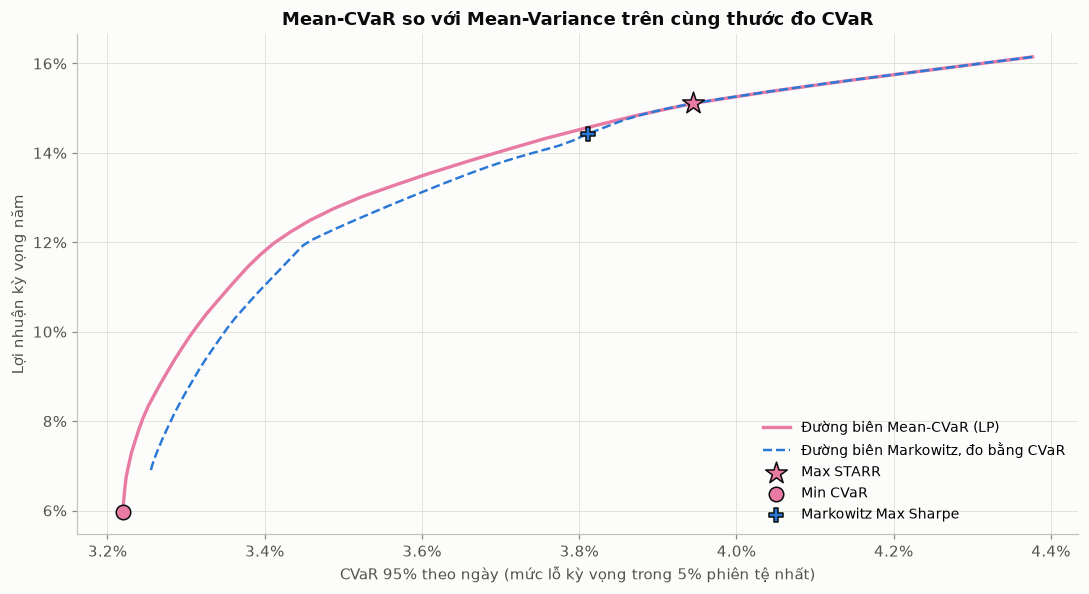

,Ngân hàng,Bất động sản,Tiêu dùng & Bán lẻ,Năng lượng & Tiện ích,Thép & Vật liệu,Công nghệ,Dịch vụ tài chính
Mean-CVaR Max STARR,24.3%,75.7%,0.0%,0.0%,0.0%,0.0%,0.0%
Mean-CVaR Min CVaR,6.7%,15.2%,49.8%,8.1%,0.0%,16.8%,3.4%
Markowitz Max Sharpe,39.9%,60.1%,0.0%,0.0%,0.0%,0.0%,0.0%
Markowitz Min Var,21.6%,12.7%,40.5%,11.3%,0.0%,11.0%,2.9%


,μ năm,σ năm,Sharpe,CVaR95 (ngày),MaxDD,ENB
Max STARR,15.11%,25.08%,0.483,3.94%,36.91%,1.581
Min CVaR,5.98%,19.71%,0.151,3.22%,27.10%,3.209
Markowitz Max Sharpe,14.42%,23.39%,0.488,3.81%,34.90%,1.922
Markowitz Min Var,6.90%,19.52%,0.200,3.26%,27.94%,3.954


LP: 1215 biến, 1206 ràng buộc bất đẳng thức | thời gian giải 33.9 ms


In [11]:
t0 = time.perf_counter(); w_cvar = mc.max_starr(R, RF_D, BETA); t_cvar = time.perf_counter() - t0
w_mincvar = mc.min_cvar(R, BETA)
cv_c, cv_r, cv_W = mc.cvar_frontier(R, BETA, n_points=40)
mv_cvar = np.array([mc.portfolio_cvar(w, R, BETA) for w in fr_W])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(cv_c, cv_r * PPY, color=viz.color("Mean-CVaR"), lw=2.2, label="Đường biên Mean-CVaR (LP)")
ax.plot(mv_cvar, fr_W @ MU, color=viz.color("Markowitz"), lw=1.6, ls="--", label="Đường biên Markowitz, đo bằng CVaR")
for name, w, mkr in [("Max STARR", w_cvar, "*"), ("Min CVaR", w_mincvar, "o"), ("Markowitz Max Sharpe", w_ms, "P")]:
    ax.scatter(mc.portfolio_cvar(w, R, BETA), w @ MU, marker=mkr, s=220 if mkr == "*" else 90,
               color=viz.color("Mean-CVaR") if name != "Markowitz Max Sharpe" else viz.color("Markowitz"),
               edgecolor=viz.INK, linewidth=1, zorder=5, label=name)
viz.pct_axis(ax, "x", 1); viz.pct_axis(ax, "y")
ax.set_xlabel(f"CVaR {BETA:.0%} theo ngày (mức lỗ kỳ vọng trong 5% phiên tệ nhất)"); ax.set_ylabel("Lợi nhuận kỳ vọng năm")
ax.set_title("Mean-CVaR so với Mean-Variance trên cùng thước đo CVaR")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

display(weight_table({"Mean-CVaR Max STARR": w_cvar, "Mean-CVaR Min CVaR": w_mincvar, "Markowitz Max Sharpe": w_ms, "Markowitz Min Var": w_mv}))
display(viz.fmt(pd.DataFrame({"Max STARR": stats_row(w_cvar), "Min CVaR": stats_row(w_mincvar),
                              "Markowitz Max Sharpe": stats_row(w_ms), "Markowitz Min Var": stats_row(w_mv)}).T,
                pct=("μ năm", "σ năm", "CVaR95 (ngày)", "MaxDD")))
print(f"LP: {len(R) + 9} biến, {len(R)} ràng buộc bất đẳng thức | thời gian giải {t_cvar*1000:.1f} ms")

## A5. HRP: phân bổ theo cấu trúc phân cấp

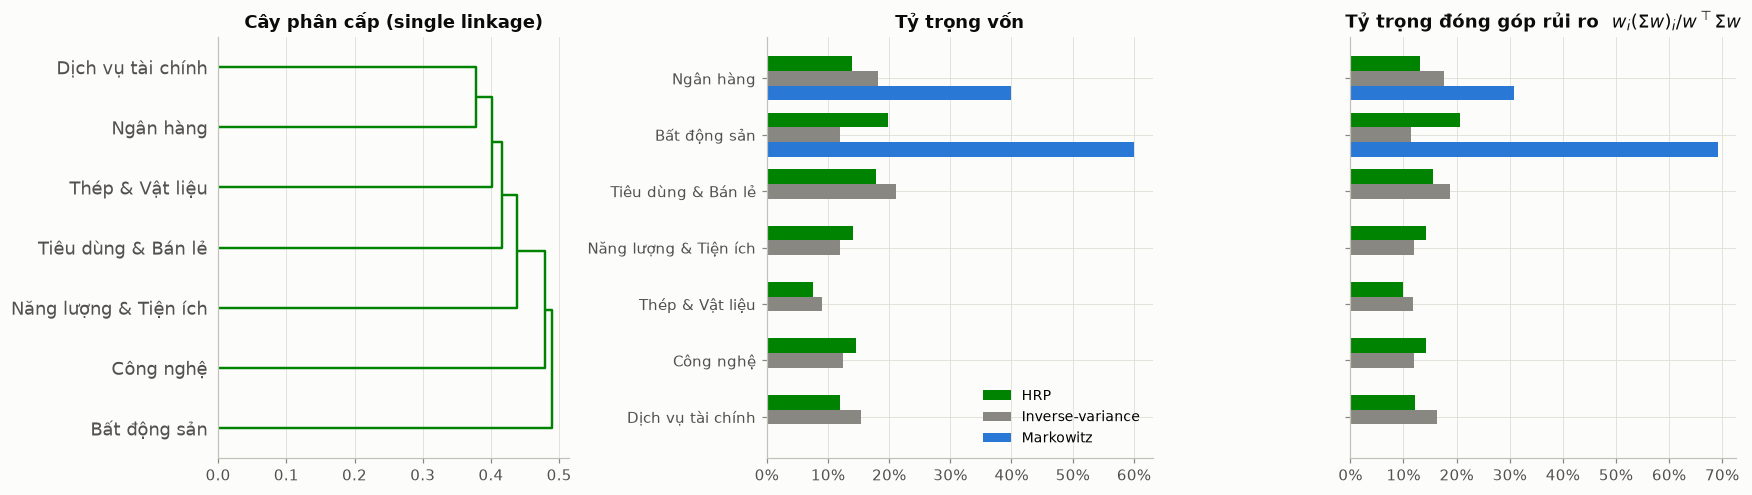

HRP: ENB = 6.56 | thời gian 0.8 ms | thứ tự quasi-diagonal: ['Bất động sản', 'Công nghệ', 'Năng lượng & Tiện ích', 'Tiêu dùng & Bán lẻ', 'Thép & Vật liệu', 'Ngân hàng', 'Dịch vụ tài chính']


In [12]:
t0 = time.perf_counter(); w_hrp, link, order = hrp.hrp_weights(COV, return_tree=True); t_hrp = time.perf_counter() - t0
w_ivp = (1 / np.diag(COV)) / (1 / np.diag(COV)).sum()

def risk_contrib(w):
    rc = w * (COV @ w)
    return rc / rc.sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
dendrogram(link, labels=LAB, ax=axes[0], orientation="right", color_threshold=0, above_threshold_color=viz.color("HRP"))
axes[0].set_title("Cây phân cấp (single linkage)"); axes[0].grid(axis="y", visible=False)

x = np.arange(7); wd = 0.26
for k, (name, w, col) in enumerate([("HRP", w_hrp, viz.color("HRP")), ("Inverse-variance", w_ivp, viz.MUTED), ("Markowitz", w_ms, viz.color("Markowitz"))]):
    axes[1].barh(x + (k - 1) * wd, w, height=wd, color=col, label=name)
    axes[2].barh(x + (k - 1) * wd, risk_contrib(w), height=wd, color=col, label=name)
for ax, t in [(axes[1], "Tỷ trọng vốn"), (axes[2], "Tỷ trọng đóng góp rủi ro  $w_i(\\Sigma w)_i / w^\\top\\Sigma w$")]:
    ax.set_yticks(x, LAB); ax.invert_yaxis(); viz.pct_axis(ax, "x"); ax.set_title(t)
axes[2].set_yticklabels([]); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
print(f"HRP: ENB = {M.enb(w_hrp):.2f} | thời gian {t_hrp*1000:.1f} ms | thứ tự quasi-diagonal: {[LAB[i] for i in order]}")

HRP **không dùng $\mu$** và không nghịch đảo $\Sigma$. Nghiệm của nó gần với inverse-variance, nhưng điều chỉnh theo cụm: các ngành thuộc cụm tài chính chặt chẽ (Ngân hàng – Dịch vụ tài chính – Thép) bị "chia phần" với nhau, còn Bất động sản và Công nghệ đứng riêng nên được giữ tỷ trọng đáng kể.

## A6. Black-Litterman: từ prior thị trường tới posterior

View: Bất động sản           vượt Dịch vụ tài chính      +33.65%/năm
View: Ngân hàng              vượt Thép & Vật liệu        +8.66%/năm


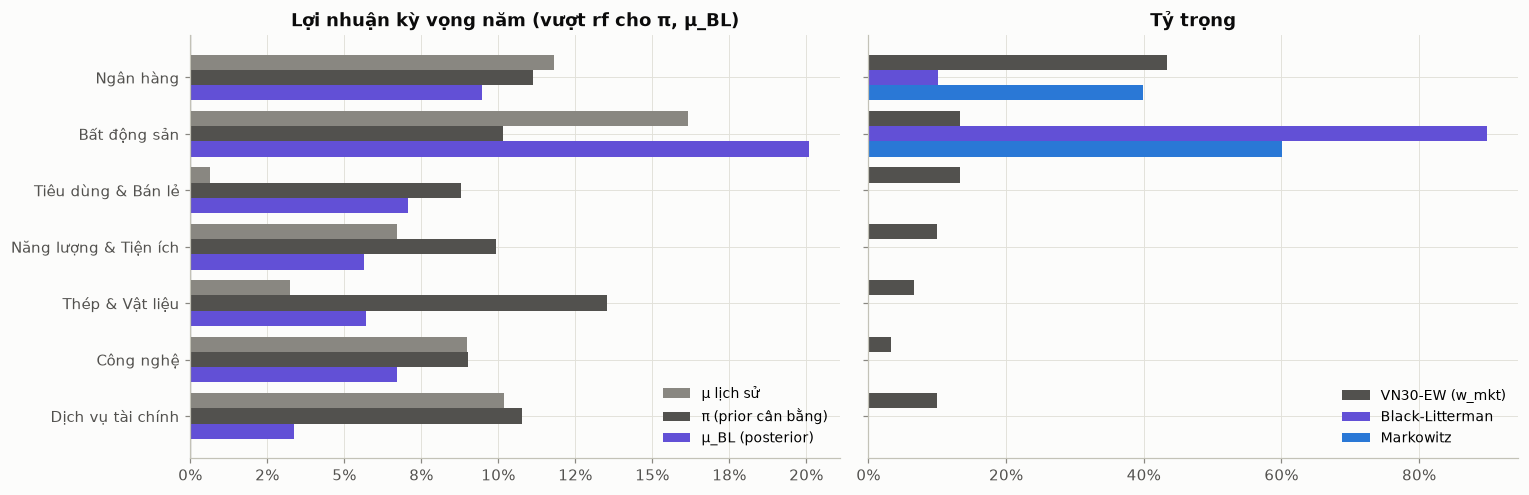

In [13]:
t0 = time.perf_counter()
(w_bl, pi, mu_bl, cov_bl), P, Q, views = bl_strategy(sec, details=True)
t_bl = time.perf_counter() - t0
for (top, bot), q in zip(views, Q):
    print(f"View: {LAB[top]:<22} vượt {LAB[bot]:<22} {q:+.2%}/năm")

mu_tbl = pd.DataFrame({"μ lịch sử": MU, "π (prior cân bằng)": pi, "μ_BL (posterior)": mu_bl}, index=LAB)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = np.arange(7); wd = 0.27
cols = [viz.MUTED, viz.INK2, viz.color("Black-Litterman")]
for k, c in enumerate(mu_tbl.columns):
    axes[0].barh(x + (k - 1) * wd, mu_tbl[c], height=wd, color=cols[k], label=c)
axes[0].set_yticks(x, LAB); axes[0].invert_yaxis(); viz.pct_axis(axes[0], "x"); axes[0].axvline(0, color=viz.INK2, lw=0.8)
axes[0].set_title("Lợi nhuận kỳ vọng năm (vượt rf cho π, μ_BL)"); axes[0].legend(loc="lower right")
for k, (name, w, col) in enumerate([("VN30-EW (w_mkt)", W_MKT, viz.INK2), ("Black-Litterman", w_bl, viz.color("Black-Litterman")),
                                     ("Markowitz", w_ms, viz.color("Markowitz"))]):
    axes[1].barh(x + (k - 1) * wd, w, height=wd, color=col, label=name)
axes[1].set_yticks(x, []); axes[1].invert_yaxis(); viz.pct_axis(axes[1], "x"); axes[1].set_title("Tỷ trọng"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

Prior $\pi$ "ngược" từ danh mục thị trường cho ra các lợi nhuận kỳ vọng **hợp lý và gần nhau** (không có ngành nào âm), trái với $\hat\mu$ lịch sử vốn rất phân tán. Views momentum chỉ **nghiêng** posterior về phía các ngành đang có xu hướng tốt. Mức độ nghiêng do $\tau$ và $\Omega$ kiểm soát.

## A7. Tổng hợp in-sample

,μ năm,σ năm,Sharpe,CVaR95 (ngày),MaxDD,ENB,Thời gian (ms),Lượt đánh giá
Markowitz,14.42%,23.39%,0.49,3.81%,34.90%,1.92,1.13,
NSGA-III,14.05%,24.10%,0.46,3.79%,27.11%,1.85,2446.79,26588.00
MAP-Elites,13.19%,21.77%,0.47,3.60%,33.51%,3.09,60.71,26608.00
CVT-MAP-Elites,13.19%,21.67%,0.47,3.60%,33.12%,3.02,2217.83,26608.00
Mean-CVaR,15.11%,25.08%,0.48,3.94%,36.91%,1.58,33.89,
HRP,8.70%,20.33%,0.28,3.41%,34.08%,6.56,0.85,
Black-Litterman,15.72%,27.06%,0.47,4.19%,41.62%,1.22,2.40,
1/N (7 ngành),8.25%,20.90%,0.25,3.53%,38.32%,7.00,,
VN30-EW,9.56%,20.61%,0.32,3.55%,37.43%,4.02,,


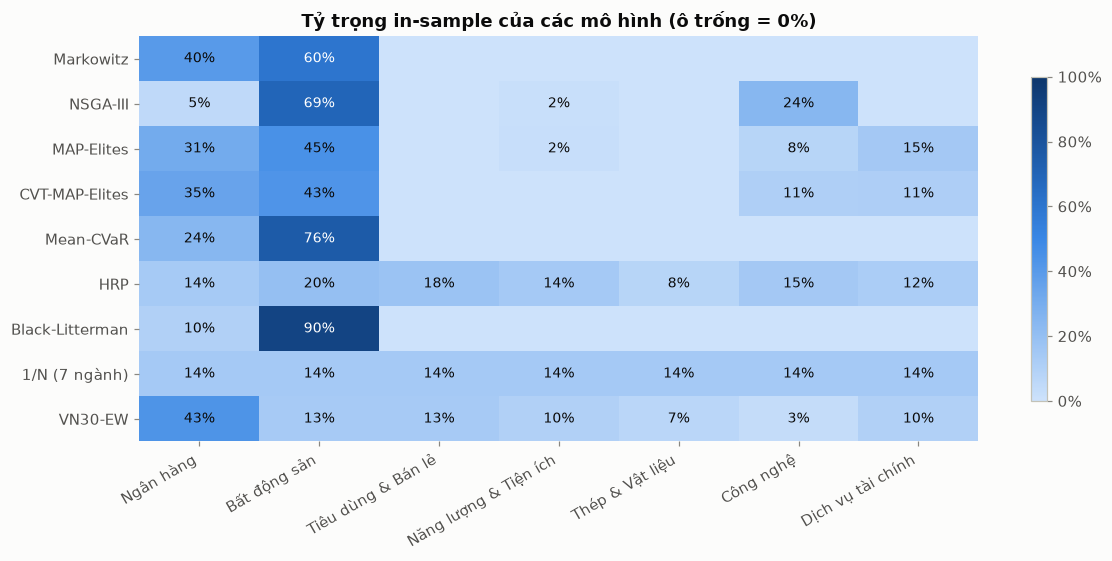

In [14]:
insample_W = {
    "Markowitz": w_ms, "NSGA-III": w_ns_calmar, "MAP-Elites": w_grid, "CVT-MAP-Elites": w_cvt,
    "Mean-CVaR": w_cvar, "HRP": w_hrp, "Black-Litterman": w_bl, "1/N (7 ngành)": w_eq, "VN30-EW": W_MKT,
}
runtime = {"Markowitz": t_mk, "NSGA-III": t_ns, "MAP-Elites": t_grid, "CVT-MAP-Elites": t_cvt,
           "Mean-CVaR": t_cvar, "HRP": t_hrp, "Black-Litterman": t_bl}
n_evals = {"NSGA-III": res_ns.n_eval, "MAP-Elites": qd_grid.n_eval, "CVT-MAP-Elites": qd_cvt.n_eval}
ins = pd.DataFrame({k: stats_row(w) for k, w in insample_W.items()}).T
ins["Thời gian (ms)"] = pd.Series(runtime) * 1000
ins["Lượt đánh giá"] = pd.Series(n_evals)
display(viz.fmt(ins, pct=("μ năm", "σ năm", "CVaR95 (ngày)", "MaxDD"), dec=2))

Wmat = pd.DataFrame(insample_W, index=LAB).T
fig, ax = plt.subplots(figsize=(11, 5.2))
im = ax.imshow(Wmat.values, cmap=viz.SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
for i in range(Wmat.shape[0]):
    for j in range(Wmat.shape[1]):
        v = Wmat.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.5 else viz.INK)
ax.set_xticks(range(7), LAB, rotation=30, ha="right"); ax.set_yticks(range(len(Wmat)), Wmat.index)
ax.grid(False); [sp.set_visible(False) for sp in ax.spines.values()]
ax.set_title("Tỷ trọng in-sample của các mô hình (ô trống = 0%)")
plt.colorbar(im, ax=ax, format=plt.matplotlib.ticker.PercentFormatter(1.0), shrink=0.8)
plt.tight_layout(); plt.show()

## A8. Độ tin cậy của các thuật toán ngẫu nhiên (10 seed, cùng ngân sách đánh giá)

Với bài toán Max Sharpe ta biết **nghiệm tối ưu toàn cục** (QP lồi), nên có thể đo chính xác chất lượng của các thuật toán tiến hóa: *Sharpe gap* = $(S^* - S)/S^*$ và khoảng cách tỷ trọng $\tfrac12\lVert w - w^*\rVert_1$. Ở đây NSGA-III dùng quy tắc chọn **max Sharpe** (không phải max Calmar) để so sánh trên cùng tiêu chí; MAP-Elites không áp ràng buộc ENB.

In [15]:
rows = []
for seed in range(10):
    t0 = time.perf_counter(); r_ = nsga3.run_nsga3(R, MU, COV, RF, seed=seed, **NSGA_KW); dt = time.perf_counter() - t0
    rows.append(("NSGA-III", seed, r_.select("max_sharpe"), dt, r_.n_eval))
    for variant, name in [("grid", "MAP-Elites"), ("cvt", "CVT-MAP-Elites")]:
        t0 = time.perf_counter(); q_ = me.run_map_elites(me.Evaluator(R, MU, COV, RF), variant=variant, seed=seed, **ME_KW)
        rows.append((name, seed, q_.select(), time.perf_counter() - t0, q_.n_eval))
seed_df = pd.DataFrame([{"Thuật toán": n, "seed": s, "Sharpe": mk.portfolio_stats(w, MU, COV, RF)[2],
                         "Sharpe gap": (sr_star - mk.portfolio_stats(w, MU, COV, RF)[2]) / sr_star,
                         "½‖w − w*‖₁": 0.5 * np.abs(w - w_ms).sum(), "Thời gian (s)": t, "Lượt đánh giá": ne}
                        for n, s, w, t, ne in rows])
agg = seed_df.groupby("Thuật toán", sort=False).agg(
    **{"Sharpe TB": ("Sharpe", "mean"), "Sharpe gap TB": ("Sharpe gap", "mean"), "Sharpe gap max": ("Sharpe gap", "max"),
       "½‖w − w*‖₁ TB": ("½‖w − w*‖₁", "mean"), "Thời gian TB (s)": ("Thời gian (s)", "mean"), "Lượt đánh giá": ("Lượt đánh giá", "mean")})
agg.loc["Markowitz (QP, chính xác)"] = [sr_star, 0, 0, 0, t_mk, np.nan]
display(viz.fmt(agg, pct=("Sharpe gap TB", "Sharpe gap max", "½‖w − w*‖₁ TB"), dec=4, pct_dec=3))

,Sharpe TB,Sharpe gap TB,Sharpe gap max,½‖w − w*‖₁ TB,Thời gian TB (s),Lượt đánh giá
Thuật toán,,,,,,
NSGA-III,0.4857,0.546%,1.318%,7.218%,2.6612,26588.0000
MAP-Elites,0.4884,0.000%,0.001%,0.107%,0.0635,26608.0000
CVT-MAP-Elites,0.4884,0.000%,0.000%,0.076%,0.1315,26608.0000
"Markowitz (QP, chính xác)",0.4884,0.000%,0.000%,0.000%,0.0011,


- Cả hai biến thể **MAP-Elites hội tụ tới nghiệm tối ưu toàn cục** ở mọi seed (gap < 0.001%). Bài toán chỉ có 7 chiều và toán tử Iso+LineDD tận dụng tốt tương quan giữa các elite.
- **NSGA-III** sai lệch trung bình khoảng 0.5% Sharpe (tối đa khoảng 1.3%), tỷ trọng lệch khoảng 7%. Lý do: NSGA-III không tối ưu Sharpe. Nó dàn quần thể đều trên mặt Pareto **3 mục tiêu**, nên vùng gần điểm tiếp tuyến chỉ có vài nghiệm.
- Về chi phí tính toán, QP chính xác nhanh hơn các thuật toán tiến hóa **hàng trăm đến hàng nghìn lần** (khoảng 1.6 ms so với 0.06–2.5 s). Với bài toán lồi, bộ giải chính xác luôn là lựa chọn đúng. Giá trị của EA nằm ở mục tiêu không lồi (MDD) và ở việc trả về **cả một tập nghiệm**.

## A9. Độ nhạy của tỷ trọng với nhiễu dữ liệu (block bootstrap)

Ta tạo 30 "lịch sử giả" bằng **circular block bootstrap** (khối 21 phiên, giữ cấu trúc cụm biến động), chạy lại từng mô hình trên mỗi mẫu, và đo mức dao động của tỷ trọng. Mô hình nào dao động ít thì **ổn định trước sai số ước lượng** (Michaud, 1998). Đây là tính chất được kỳ vọng sẽ chuyển thành turnover thấp và hiệu quả tốt hơn ngoài mẫu.

Bootstrap 30 mẫu x 7 mô hình: 81 s


,Std TB của tỷ trọng (điểm %),Turnover TB so với nghiệm gốc,ENB TB
HRP,1.41,3.69%,6.50
CVT-MAP-Elites,13.23,46.08%,3.08
MAP-Elites,13.27,46.98%,3.09
Markowitz,20.64,63.32%,1.80
NSGA-III,21.17,59.38%,1.83
Mean-CVaR,21.93,66.13%,1.57
Black-Litterman,24.13,71.26%,1.75


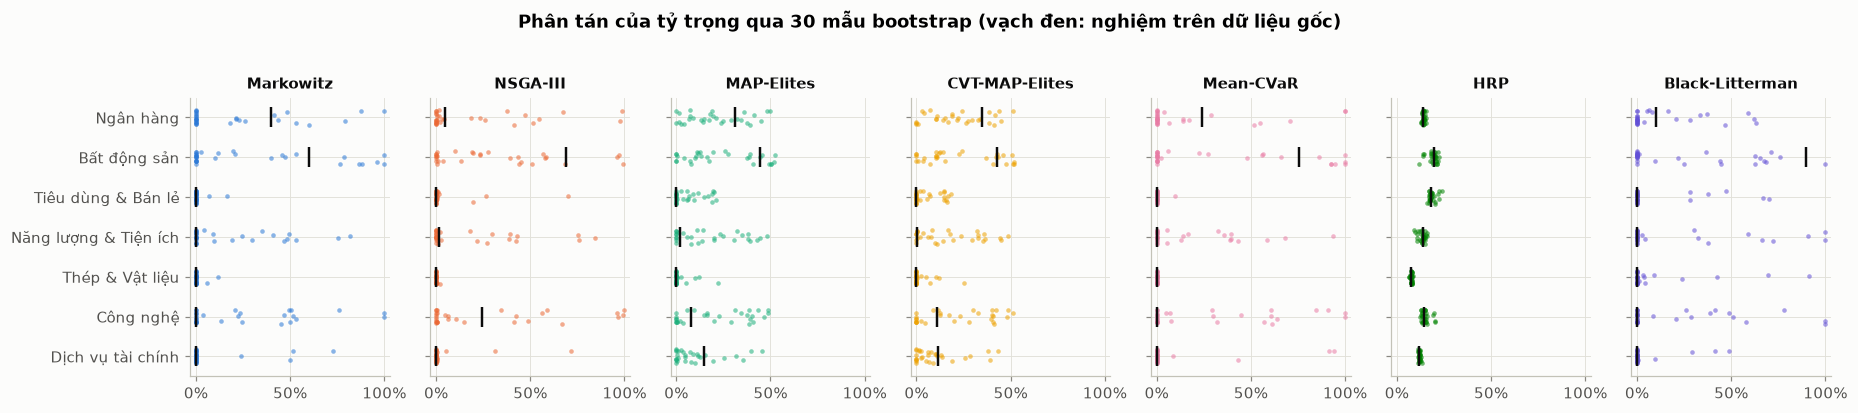

In [16]:
def block_resample(df, rng, block=21):
    T = len(df)
    starts = rng.integers(0, T, size=int(np.ceil(T / block)))
    idx = (starts[:, None] + np.arange(block)[None, :]).ravel()[:T] % T
    return pd.DataFrame(df.to_numpy()[idx], columns=df.columns, index=df.index)

rng = np.random.default_rng(SEED)
N_BOOT = 30
boot_W = {m: [] for m in MODELS}
t0 = time.perf_counter()
for b in range(N_BOOT):
    sample = block_resample(sec, rng)
    for m in MODELS:
        boot_W[m].append(STRATEGIES[m](sample))
print(f"Bootstrap {N_BOOT} mẫu x {len(MODELS)} mô hình: {time.perf_counter() - t0:.0f} s")

stab = pd.DataFrame({m: {
    "Std TB của tỷ trọng (điểm %)": np.std(np.array(boot_W[m]), axis=0).mean() * 100,
    "Turnover TB so với nghiệm gốc": np.mean([0.5 * np.abs(w - insample_W[m]).sum() for w in boot_W[m]]),
    "ENB TB": np.mean([M.enb(w) for w in boot_W[m]]),
} for m in MODELS}).T.sort_values("Std TB của tỷ trọng (điểm %)")
display(viz.fmt(stab, pct=("Turnover TB so với nghiệm gốc",), dec=2))

fig, axes = plt.subplots(1, len(MODELS), figsize=(17, 3.6), sharey=True)
for ax, m in zip(axes, MODELS):
    Wb = np.array(boot_W[m])
    for j in range(7):
        ax.scatter(Wb[:, j], np.full(len(Wb), j) + np.random.default_rng(j).uniform(-0.18, 0.18, len(Wb)),
                   s=9, color=viz.color(m), alpha=0.55, linewidths=0)
    ax.scatter(insample_W[m], np.arange(7), marker="|", s=160, color=viz.INK, linewidths=1.6, zorder=4)
    ax.set_title(m, fontsize=10); viz.pct_axis(ax, "x"); ax.set_xlim(-0.03, 1.03)
axes[0].set_yticks(range(7), LAB); axes[0].invert_yaxis()
fig.suptitle("Phân tán của tỷ trọng qua 30 mẫu bootstrap (vạch đen: nghiệm trên dữ liệu gốc)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

- **HRP ổn định vượt trội**: độ lệch chuẩn tỷ trọng khoảng 1.4 điểm %, so với khoảng 20–24 điểm % của các mô hình dùng $\hat\mu$ (Markowitz, NSGA-III, Mean-CVaR, Black-Litterman). Chỉ cần nhiễu lấy mẫu là nghiệm Max Sharpe có thể nhảy từ 0% lên 100% ở cùng một ngành.
- MAP-Elites/CVT với ràng buộc ENB ≥ 3 nằm ở giữa (khoảng 13 điểm %): ràng buộc đa dạng hóa **chặn các nghiệm góc**, nên giảm một phần độ nhạy với $\hat\mu$.
- Black-Litterman *kém* ổn định nhất ở đây. Lý do là views momentum được tính lại trên mỗi mẫu bootstrap và chiếm ưu thế so với prior (tham số `scale = 0.5`, $\tau = 0.05$). Nếu giữ views cố định, BL sẽ ổn định hơn nhiều.

---
# PHẦN B — BACKTEST WALK-FORWARD (OUT-OF-SAMPLE)

- Cửa sổ ước lượng: **484 phiên (~2 năm)**, trượt theo thời gian. Tái cân bằng mỗi **21 phiên**.
- Giữa hai lần tái cân bằng tỷ trọng **trôi theo giá** (buy-and-hold), không tái cân bằng ngầm hằng ngày.
- Phí giao dịch: **20 bps × turnover một chiều**, trừ vào phiên đầu tiên sau mỗi lần tái cân bằng.
- Mọi mô hình dùng **cùng dữ liệu, cùng ngày tái cân bằng, cùng ước lượng $\hat\mu, \hat\Sigma$**. Khác biệt duy nhất là thuật toán phân bổ.

In [17]:
print(f"Giai đoạn out-of-sample: {sec.index[LOOKBACK].date()} -> {sec.index[-1].date()} "
      f"({len(sec) - LOOKBACK} phiên, {(len(sec) - LOOKBACK) / PPY:.1f} năm, {int(np.ceil((len(sec) - LOOKBACK) / REBAL))} lần tái cân bằng)")
t0 = time.perf_counter()
results = bt.run_all(sec, STRATEGIES, lookback=LOOKBACK, rebalance_every=REBAL, cost_bps=COST_BPS)
print(f"Tổng thời gian: {time.perf_counter() - t0:.0f} s")
oos = pd.DataFrame({k: r.returns for k, r in results.items()})
OOS_YEARS = len(oos) / PPY

Giai đoạn out-of-sample: 2023-10-05 -> 2026-10-09 (722 phiên, 3.0 năm, 35 lần tái cân bằng)
  Markowitz          xong sau    0.0s


  NSGA-III           xong sau   77.6s


  MAP-Elites         xong sau    2.0s


  CVT-MAP-Elites     xong sau    4.9s


  Mean-CVaR          xong sau    0.4s
  HRP                xong sau    0.0s
  Black-Litterman    xong sau    0.1s
  1/N (7 ngành)      xong sau    0.0s
  VN30-EW            xong sau    0.0s
Tổng thời gian: 85 s


## B1. Bảng kết quả chính (sau phí giao dịch)

In [18]:
perf = M.summary(oos, RF, PPY, BETA)
perf["Turnover/năm"] = pd.Series({k: r.turnover.iloc[1:].sum() / OOS_YEARS for k, r in results.items()})
perf["ENB TB"] = pd.Series({k: np.mean([M.enb(w) for w in r.weights.to_numpy()]) for k, r in results.items()})
perf["ms / lần tối ưu"] = pd.Series({k: r.runtime / len(r.weights) * 1000 for k, r in results.items()})
ci = {k: M.block_bootstrap_sharpe(oos[k], RF, PPY, n_boot=3000, block=21, seed=SEED) for k in oos}
perf["Sharpe CI95 thấp"] = pd.Series({k: v[0] for k, v in ci.items()})
perf["Sharpe CI95 cao"] = pd.Series({k: v[1] for k, v in ci.items()})
perf["p-value JK (vs 1/N)"] = pd.Series({k: M.jobson_korkie_memmel(oos[k], oos["1/N (7 ngành)"], RF, PPY)[1] for k in oos})
perf = perf.sort_values("Sharpe", ascending=False)
show_cols = ["CAGR", "Volatility", "Sharpe", "Sharpe CI95 thấp", "Sharpe CI95 cao", "p-value JK (vs 1/N)", "Sortino",
             "MaxDD", "Calmar", "CVaR95", "Turnover/năm", "ENB TB", "ms / lần tối ưu"]
display(viz.fmt(perf[show_cols], pct=("CAGR", "Volatility", "MaxDD", "CVaR95", "Turnover/năm"), dec=3))

,CAGR,Volatility,Sharpe,Sharpe CI95 thấp,Sharpe CI95 cao,p-value JK (vs 1/N),Sortino,MaxDD,Calmar,CVaR95,Turnover/năm,ENB TB,ms / lần tối ưu
Black-Litterman,32.47%,29.07%,1.011,-0.147,2.131,0.348,1.493,28.50%,1.139,4.31%,327.87%,1.474,1.391
VN30-EW,16.46%,19.14%,0.738,-0.386,1.962,0.404,0.997,18.62%,0.884,3.14%,17.61%,4.018,0.001
HRP,14.95%,19.46%,0.662,-0.505,1.925,0.503,0.908,22.49%,0.665,3.11%,50.13%,6.446,0.759
NSGA-III,17.69%,27.10%,0.628,-0.491,1.784,0.990,0.887,31.87%,0.555,4.23%,132.82%,1.660,2216.030
1/N (7 ngành),14.23%,19.75%,0.623,-0.537,1.877,,0.854,23.01%,0.618,3.16%,21.02%,7.000,0.005
CVT-MAP-Elites,15.37%,22.74%,0.613,-0.517,1.786,0.968,0.856,23.04%,0.667,3.59%,122.50%,3.096,138.718
MAP-Elites,14.69%,22.94%,0.584,-0.550,1.757,0.879,0.815,23.56%,0.624,3.63%,109.16%,3.090,58.239
Markowitz,16.54%,28.39%,0.577,-0.563,1.697,0.908,0.833,31.67%,0.522,4.27%,126.87%,1.336,1.087
Mean-CVaR,14.55%,29.51%,0.508,-0.624,1.630,0.779,0.725,31.89%,0.456,4.53%,105.53%,1.201,11.174


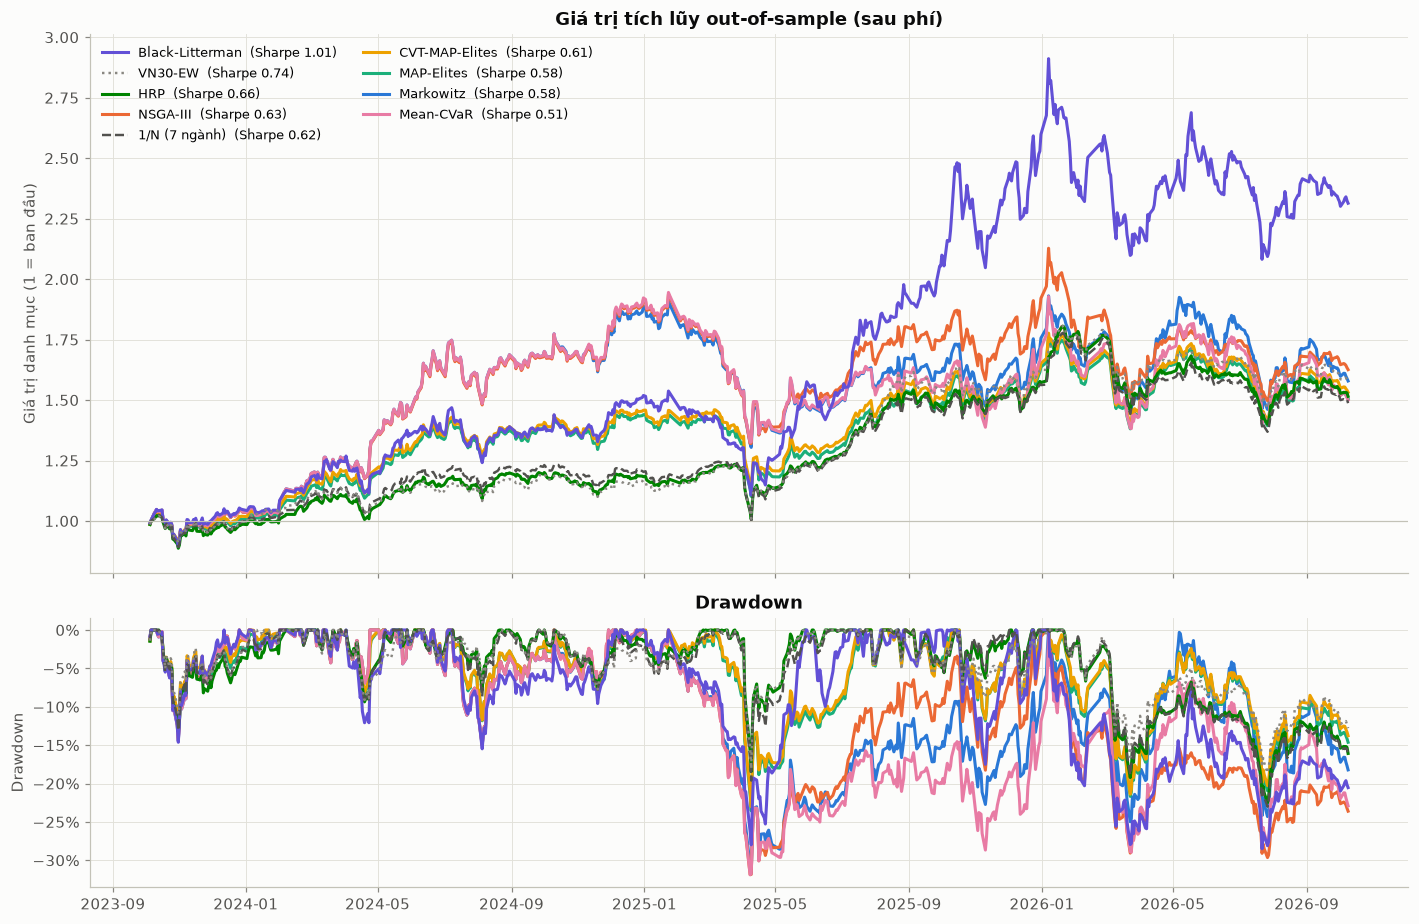

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
order_ = list(perf.index)
for k in ALL:
    w = (1 + oos[k]).cumprod()
    kw = dict(color=viz.color(k), lw=2.0 if k in MODELS else 1.6, ls=viz.LINESTYLE.get(k, "-"))
    axes[0].plot(w.index, w, label=f"{k}  (Sharpe {perf.loc[k, 'Sharpe']:.2f})", **kw)
    axes[1].plot(w.index, M.drawdown(oos[k].values), **kw)
axes[0].axhline(1, color=viz.AXIS, lw=0.8)
axes[0].set_ylabel("Giá trị danh mục (1 = ban đầu)"); axes[0].set_title("Giá trị tích lũy out-of-sample (sau phí)")
handles, labels = axes[0].get_legend_handles_labels()
idx_sorted = [labels.index(next(l for l in labels if l.startswith(k + "  "))) for k in order_]
axes[0].legend([handles[i] for i in idx_sorted], [labels[i] for i in idx_sorted], loc="upper left", ncol=2, fontsize=8.5)
viz.pct_axis(axes[1]); axes[1].set_ylabel("Drawdown"); axes[1].set_title("Drawdown")
plt.tight_layout(); plt.show()

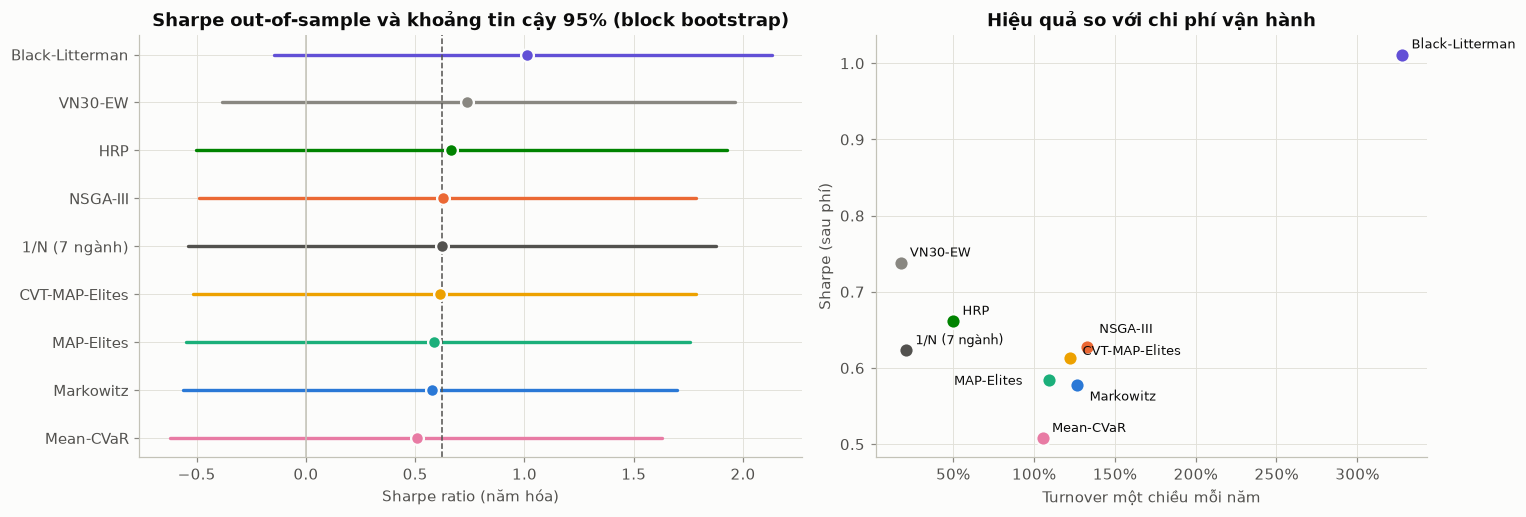

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
yy = np.arange(len(perf))[::-1]
for y, k in zip(yy, perf.index):
    lo, hi = perf.loc[k, "Sharpe CI95 thấp"], perf.loc[k, "Sharpe CI95 cao"]
    ax.plot([lo, hi], [y, y], color=viz.color(k), lw=2.2, solid_capstyle="round")
    ax.scatter(perf.loc[k, "Sharpe"], y, s=70, color=viz.color(k), edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
ax.axvline(perf.loc["1/N (7 ngành)", "Sharpe"], color=viz.INK2, ls="--", lw=1)
ax.axvline(0, color=viz.AXIS, lw=1)
ax.set_yticks(yy, perf.index); ax.set_xlabel("Sharpe ratio (năm hóa)")
ax.set_title("Sharpe out-of-sample và khoảng tin cậy 95% (block bootstrap)")

ax = axes[1]
for k in perf.index:
    ax.scatter(perf.loc[k, "Turnover/năm"], perf.loc[k, "Sharpe"], s=90, color=viz.color(k), edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
    off = {"CVT-MAP-Elites": (8, 2), "NSGA-III": (8, 9), "MAP-Elites": (-62, -3), "Markowitz": (8, -10)}.get(k, (6, 4))
    ax.annotate(k, (perf.loc[k, "Turnover/năm"], perf.loc[k, "Sharpe"]), xytext=off, textcoords="offset points", fontsize=8.5, color=viz.INK)
viz.pct_axis(ax, "x"); ax.set_xlabel("Turnover một chiều mỗi năm"); ax.set_ylabel("Sharpe (sau phí)")
ax.set_title("Hiệu quả so với chi phí vận hành")
plt.tight_layout(); plt.show()

## B2. Tỷ trọng theo thời gian

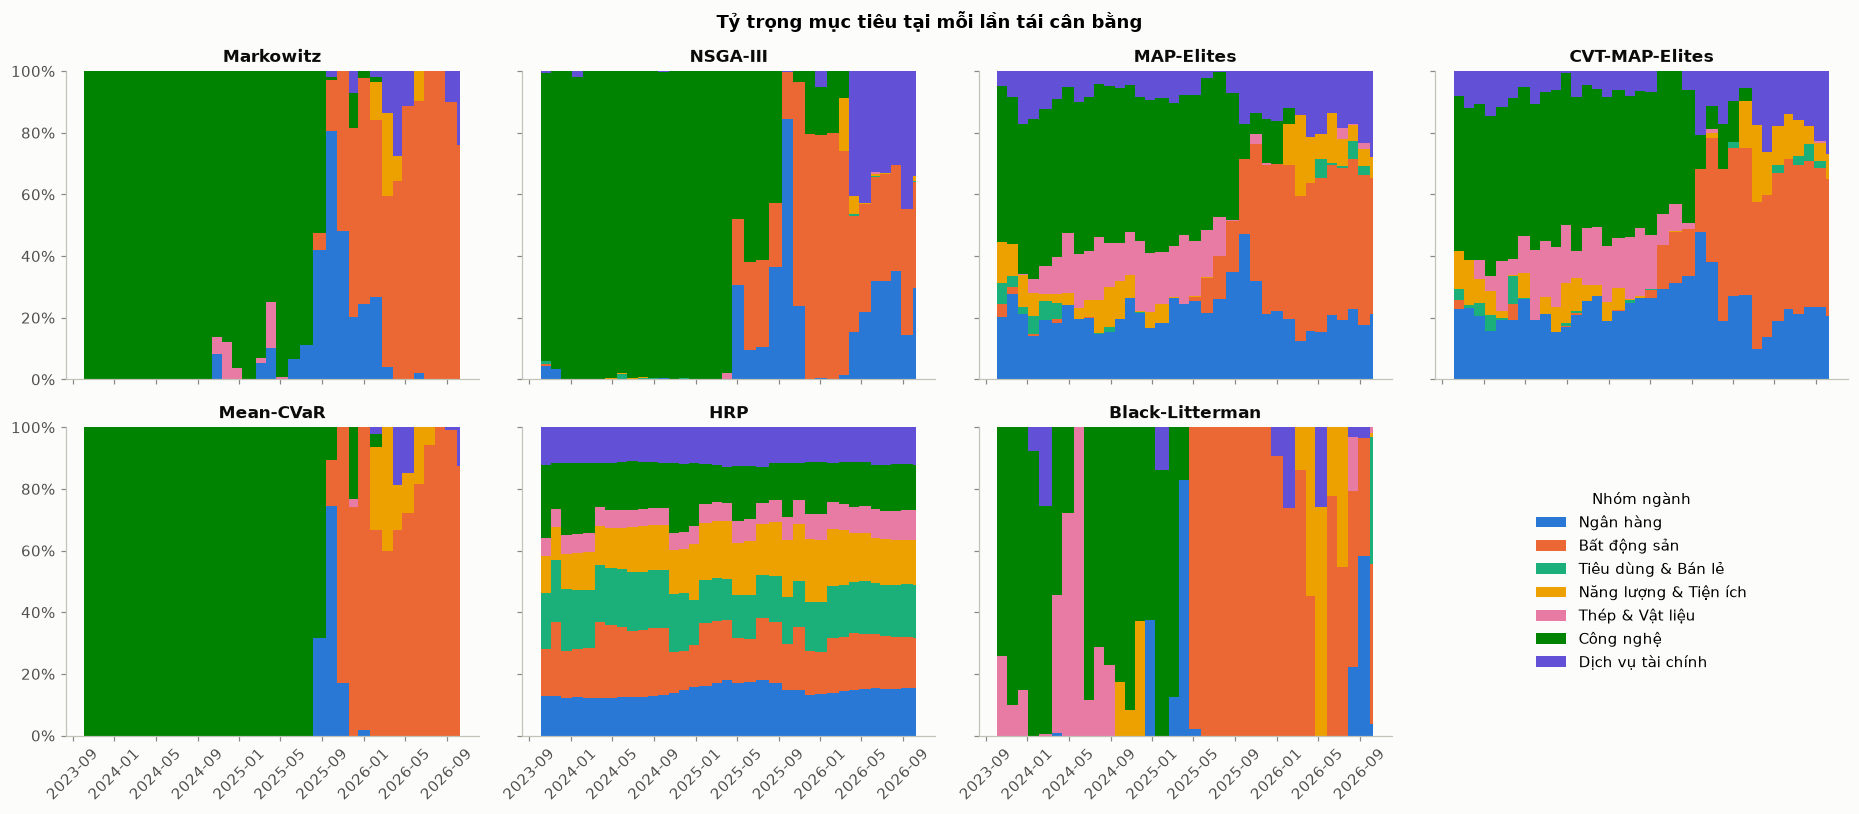

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True, sharey=True)
for ax, m in zip(axes.ravel(), MODELS):
    Wt = results[m].weights
    dates = list(Wt.index) + [oos.index[-1]]
    base = np.zeros(len(dates))
    for j, s in enumerate(SECTORS):
        vals = np.r_[Wt[s].to_numpy(), Wt[s].to_numpy()[-1]]
        ax.fill_between(dates, base, base + vals, step="post", color=SEC_COLORS[s], linewidth=0, label=VI[s])
        base = base + vals
    ax.set_title(m, fontsize=11); viz.pct_axis(ax); ax.set_ylim(0, 1); ax.grid(False)
    ax.tick_params(axis="x", rotation=45)
ax_leg = axes.ravel()[-1]; ax_leg.axis("off")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
ax_leg.legend(handles, labels, loc="center", fontsize=10, title="Nhóm ngành")
fig.suptitle("Tỷ trọng mục tiêu tại mỗi lần tái cân bằng", fontweight="bold")
plt.tight_layout(); plt.show()

## B3. Hiệu quả theo từng năm (out-of-sample)

In [22]:
yr = (1 + oos).groupby(oos.index.year).prod() - 1
cnt = oos.groupby(oos.index.year).size()
yr.index = [f"{y} ({n} phiên)" for y, n in cnt.items()]
display(viz.fmt(yr.T.loc[perf.index], pct=yr.index, pct_dec=1))

,2023 (62 phiên),2024 (247 phiên),2025 (227 phiên),2026 (186 phiên)
Black-Litterman,4.7%,45.1%,71.1%,-11.0%
VN30-EW,-0.2%,16.1%,40.2%,-3.1%
HRP,-1.4%,19.9%,32.9%,-3.6%
NSGA-III,3.6%,84.8%,0.3%,-15.4%
1/N (7 ngành),-0.1%,20.4%,29.9%,-4.8%
CVT-MAP-Elites,1.9%,43.0%,13.3%,-7.3%
MAP-Elites,0.7%,43.0%,13.7%,-8.0%
Markowitz,3.8%,81.9%,-7.0%,-10.1%
Mean-CVaR,3.8%,85.2%,-10.9%,-12.5%


## B4. Độ nhạy theo chi phí giao dịch và theo độ dài cửa sổ ước lượng

In [23]:
cost_grid = [0, 10, 20, 50, 100]
cost_tbl = pd.DataFrame({f"{c} bps": {k: M.sharpe(bt.apply_costs(r, c), RF, PPY) for k, r in results.items()} for c in cost_grid})
print("Sharpe out-of-sample theo mức phí giao dịch:")
display(viz.fmt(cost_tbl.loc[perf.index], dec=3))

Sharpe out-of-sample theo mức phí giao dịch:


,0 bps,10 bps,20 bps,50 bps,100 bps
Black-Litterman,1.035,1.023,1.011,0.976,0.915
VN30-EW,0.742,0.740,0.738,0.733,0.724
HRP,0.669,0.665,0.662,0.651,0.634
NSGA-III,0.639,0.634,0.628,0.611,0.584
1/N (7 ngành),0.627,0.625,0.623,0.617,0.608
CVT-MAP-Elites,0.625,0.619,0.613,0.595,0.564
MAP-Elites,0.595,0.589,0.584,0.567,0.540
Markowitz,0.587,0.582,0.577,0.562,0.537
Mean-CVaR,0.516,0.512,0.508,0.496,0.475


In [24]:
t0 = time.perf_counter()
results_1y = bt.run_all(sec, STRATEGIES, verbose=False, lookback=242, rebalance_every=REBAL, cost_bps=COST_BPS, start=LOOKBACK)
print(f"Chạy lại với cửa sổ 1 năm: {time.perf_counter() - t0:.0f} s (cùng giai đoạn out-of-sample)")
lb_tbl = pd.DataFrame({
    "Sharpe — cửa sổ 1 năm": {k: M.sharpe(r.returns, RF, PPY) for k, r in results_1y.items()},
    "Sharpe — cửa sổ 2 năm": perf["Sharpe"],
    "MaxDD — cửa sổ 1 năm": {k: M.max_drawdown(r.returns) for k, r in results_1y.items()},
    "MaxDD — cửa sổ 2 năm": perf["MaxDD"],
    "Turnover/năm — 1 năm": {k: r.turnover.iloc[1:].sum() / OOS_YEARS for k, r in results_1y.items()},
    "Turnover/năm — 2 năm": perf["Turnover/năm"],
}).loc[perf.index]
display(viz.fmt(lb_tbl, pct=[c for c in lb_tbl.columns if "MaxDD" in c or "Turnover" in c], dec=3))

Chạy lại với cửa sổ 1 năm: 86 s (cùng giai đoạn out-of-sample)


,Sharpe — cửa sổ 1 năm,Sharpe — cửa sổ 2 năm,MaxDD — cửa sổ 1 năm,MaxDD — cửa sổ 2 năm,Turnover/năm — 1 năm,Turnover/năm — 2 năm
Black-Litterman,1.114,1.011,27.37%,28.50%,334.31%,327.87%
VN30-EW,0.738,0.738,18.62%,18.62%,17.61%,17.61%
HRP,0.691,0.662,23.07%,22.49%,52.66%,50.13%
NSGA-III,1.209,0.628,29.12%,31.87%,231.76%,132.82%
1/N (7 ngành),0.623,0.623,23.01%,23.01%,21.02%,21.02%
CVT-MAP-Elites,1.067,0.613,23.43%,23.04%,158.09%,122.50%
MAP-Elites,1.050,0.584,24.19%,23.56%,127.33%,109.16%
Markowitz,1.154,0.577,31.23%,31.67%,175.72%,126.87%
Mean-CVaR,1.182,0.508,32.30%,31.89%,134.02%,105.53%


## B5. Ablation: quy tắc chọn nghiệm của các thuật toán tiến hóa

NSGA-III và MAP-Elites trả về **một tập** nghiệm; danh mục cuối cùng phụ thuộc vào quy tắc chọn. Ta so sánh quy tắc đã định trước với phương án "chọn Sharpe cao nhất". Các phương án này dùng lại đúng kết quả tối ưu đã cache, nên chỉ quy tắc chọn là thay đổi.

In [25]:
ABLATION = {
    "NSGA-III · max Calmar (chính)":      STRATEGIES["NSGA-III"],
    "NSGA-III · max Sharpe":              lambda w: run_nsga(w).select("max_sharpe"),
    "MAP-Elites · ENB≥3 (chính)":         STRATEGIES["MAP-Elites"],
    "MAP-Elites · max Sharpe":            lambda w: run_me(w, "grid").select(),
    "CVT-MAP-Elites · ENB≥3 (chính)":     STRATEGIES["CVT-MAP-Elites"],
    "CVT-MAP-Elites · max Sharpe":        lambda w: run_me(w, "cvt").select(),
    "Markowitz (tham chiếu)":             STRATEGIES["Markowitz"],
}
res_ab = bt.run_all(sec, ABLATION, verbose=False, lookback=LOOKBACK, rebalance_every=REBAL, cost_bps=COST_BPS)
ab = M.summary(pd.DataFrame({k: r.returns for k, r in res_ab.items()}), RF, PPY, BETA)[["CAGR", "Volatility", "Sharpe", "MaxDD", "Calmar", "CVaR95"]]
ab["Turnover/năm"] = pd.Series({k: r.turnover.iloc[1:].sum() / OOS_YEARS for k, r in res_ab.items()})
ab["ENB TB"] = pd.Series({k: np.mean([M.enb(w) for w in r.weights.to_numpy()]) for k, r in res_ab.items()})
display(viz.fmt(ab, pct=("CAGR", "Volatility", "MaxDD", "CVaR95", "Turnover/năm"), dec=3))

,CAGR,Volatility,Sharpe,MaxDD,Calmar,CVaR95,Turnover/năm,ENB TB
NSGA-III · max Calmar (chính),17.69%,27.10%,0.628,31.87%,0.555,4.23%,132.82%,1.660
NSGA-III · max Sharpe,15.81%,28.60%,0.553,32.59%,0.485,4.32%,141.46%,1.319
MAP-Elites · ENB≥3 (chính),14.69%,22.94%,0.584,23.56%,0.624,3.63%,109.16%,3.090
MAP-Elites · max Sharpe,16.44%,28.39%,0.574,31.67%,0.519,4.27%,127.60%,1.338
CVT-MAP-Elites · ENB≥3 (chính),15.37%,22.74%,0.613,23.04%,0.667,3.59%,122.50%,3.096
CVT-MAP-Elites · max Sharpe,16.60%,28.37%,0.579,31.69%,0.524,4.26%,127.13%,1.339
Markowitz (tham chiếu),16.54%,28.39%,0.577,31.67%,0.522,4.27%,126.87%,1.336


## B6. Xếp hạng tổng hợp

In [26]:
crit = {"Sharpe": False, "Sortino": False, "Calmar": False, "MaxDD": True, "CVaR95": True, "Turnover/năm": True}
ranks = pd.DataFrame({c: perf[c].rank(ascending=asc) for c, asc in crit.items()})
ranks["Hạng TB"] = ranks.mean(axis=1)
ranks = ranks.sort_values("Hạng TB")
display(viz.fmt(ranks.astype(float), dec=1))

,Sharpe,Sortino,Calmar,MaxDD,CVaR95,Turnover/năm,Hạng TB
VN30-EW,2.0,2.0,2.0,1.0,2.0,1.0,1.7
HRP,3.0,3.0,4.0,2.0,1.0,3.0,2.7
1/N (7 ngành),5.0,6.0,6.0,3.0,3.0,2.0,4.2
Black-Litterman,1.0,1.0,1.0,6.0,8.0,9.0,4.3
CVT-MAP-Elites,6.0,5.0,3.0,4.0,4.0,6.0,4.7
MAP-Elites,7.0,8.0,5.0,5.0,5.0,5.0,5.8
NSGA-III,4.0,4.0,7.0,8.0,6.0,8.0,6.2
Markowitz,8.0,7.0,8.0,7.0,7.0,7.0,7.3
Mean-CVaR,9.0,9.0,9.0,9.0,9.0,4.0,8.2


## B7. Kết luận

*(Phần này được viết dựa trên kết quả đã chạy ở trên; nếu thay đổi tham số hoặc dữ liệu, cần đọc lại các bảng để cập nhật nhận xét.)*

### 1. Không mô hình nào vượt 1/N một cách có ý nghĩa thống kê
Trong 3 năm out-of-sample (10/2023 – 10/2026, 35 lần tái cân bằng), **khoảng tin cậy 95% của Sharpe ở mọi chiến lược đều chứa cả 0 lẫn Sharpe của 1/N**. Kiểm định Jobson–Korkie–Memmel so với 1/N cho p-value ≥ 0.35 ở tất cả mô hình. Với chỉ 3 năm dữ liệu kiểm tra, chênh lệch Sharpe cỡ 0.3–0.4 **không đủ để khẳng định** mô hình nào tốt hơn. Kết quả này phù hợp với DeMiguel, Garlappi & Uppal (2009). Mọi xếp hạng bên dưới chỉ nên được đọc như **bằng chứng định tính**.

### 2. Kết quả chính theo từng mô hình

| Mô hình | Sharpe OOS | MaxDD | Turnover/năm | Nhận xét |
|---|---|---|---|---|
| **HRP** | 0.66 | 22.5% | 50% | Hồ sơ rủi ro tốt nhất trong 7 mô hình: CVaR thấp nhất (3.11%/ngày), MDD thấp thứ 2, Sharpe > 1/N, turnover thấp, tỷ trọng ổn định nhất (bootstrap). Gần như không đổi khi đổi cửa sổ 1 năm ↔ 2 năm. |
| **Black-Litterman** | **1.01** | 28.5% | **328%** | Sharpe và CAGR (32.5%) cao nhất, nhưng thực chất là một **chiến lược momentum tập trung** (ENB TB 1.47): dồn gần 100% vào Bất động sản trong đợt tăng +169% năm 2025. p-value so với 1/N = 0.35. Đây là một cược đúng *trong giai đoạn này*, chưa phải bằng chứng về độ bền. |
| **CVT-MAP-Elites** (ENB ≥ 3) | 0.61 | 23.0% | 123% | So với Markowitz: Sharpe tương đương, nhưng **vol giảm 28.4% → 22.7%, MDD giảm 31.7% → 23.0%**, nhờ ràng buộc đa dạng hóa áp lên archive. |
| **MAP-Elites** (ENB ≥ 3) | 0.58 | 23.6% | 109% | Giống CVT. Grid nhanh hơn khoảng 30 lần (không cần k-means) nhưng chỉ phủ 42% số ô (CVT phủ 100%). |
| **NSGA-III** (max Calmar) | 0.63 | 31.9% | 133% | Quy tắc chọn theo MDD **tốt hơn** chọn theo Sharpe (0.63 so với 0.55, ablation B5). Tuy vậy MDD ngoài mẫu vẫn cao: MDD trong mẫu là một thống kê rất nhiễu. |
| **Markowitz** (Max Sharpe) | 0.58 | 31.7% | 127% | Nắm **100% Công nghệ (FPT)** gần 2 năm (10/2023 – 7/2025): lãi lớn năm 2024 (+82%) rồi lỗ năm 2025 (−7%) khi FPT giảm. Đúng là "bộ khuếch đại sai số ước lượng". |
| **Mean-CVaR** (Max STARR) | 0.51 | 31.9% | 106% | Nghiệm gần như trùng Markowitz (cũng là nghiệm góc). CVaR ngoài mẫu **không** thấp hơn (4.53% so với 4.27%), vì CVaR 95% trên 484 phiên chỉ dựa vào khoảng 24 kịch bản đuôi, còn nhiễu hơn cả phương sai. |
| 1/N · VN30-EW | 0.62 · 0.74 | 23.0% · 18.6% | 21% · 18% | Hai benchmark đơn giản đứng **hạng 3 và hạng 1** trong bảng xếp hạng tổng hợp 6 tiêu chí. |

### 3. Bài học về tối ưu hóa
1. **Sai số ước lượng quan trọng hơn thuật toán.** Các mô hình dùng $\hat\mu$ (Markowitz, Mean-CVaR, NSGA-III, MAP-Elites) **đổi kết quả hoàn toàn khi chỉ đổi độ dài cửa sổ**: Sharpe của Markowitz là 0.58 với cửa sổ 2 năm nhưng 1.15 với cửa sổ 1 năm, Mean-CVaR là 0.51 so với 1.18. Trong khi đó HRP (0.66 / 0.69) và 1/N (không đổi) gần như bất biến. Một kết quả nhạy như vậy với một siêu tham số **không thể dùng để kết luận** rằng mô hình tốt hay xấu.
2. **Bài toán lồi → bộ giải chính xác.** QP/LP giải Max Sharpe / Max STARR trong 2–30 ms và cho tối ưu toàn cục. MAP-Elites đạt cùng nghiệm nhưng tốn khoảng 26.6k lượt đánh giá; NSGA-III vẫn còn gap khoảng 0.5%.
3. **Giá trị thực của thuật toán tiến hóa / QD** là ở những thứ QP không làm được: tối ưu **mục tiêu không lồi** (MDD), và trả về **một tập nghiệm đa dạng** để áp ràng buộc *sau khi* tối ưu. Đường "giá của đa dạng hóa" (A3) cho thấy tăng ENB từ 1.9 lên 3 chỉ tốn khoảng 4% Sharpe trong mẫu. Ở ngoài mẫu, chính lựa chọn đó cắt được khoảng 8 điểm % MDD.
4. **Ràng buộc đa dạng hóa là một dạng regularization.** Các chiến lược ENB cao (HRP, 1/N, VN30-EW, MAP-Elites/CVT với ENB ≥ 3) đều có MDD 19–24%, còn các chiến lược tập trung (ENB < 2) đều có MDD 28–32%.

### 4. Khuyến nghị
Với dữ liệu này (N = 7, tương quan cao, $\hat\mu$ nhiễu): nếu ưu tiên **độ bền và rủi ro thấp**, chọn **HRP** (hoặc đơn giản là VN30-EW / 1/N). Nếu vẫn muốn dùng $\hat\mu$, cần **thêm ràng buộc đa dạng hóa** (ENB tối thiểu, trần tỷ trọng $w_{max}$). Khi đó các mô hình QD như CVT-MAP-Elites là công cụ tự nhiên để khảo sát đánh đổi Sharpe ↔ đa dạng hóa. Kết quả của Black-Litterman cho thấy views có thể tạo giá trị lớn, nhưng nó phụ thuộc hoàn toàn vào chất lượng views và cần kiểm định trên giai đoạn dài hơn.

### 5. Hạn chế & hướng phát triển
- **Out-of-sample chỉ 3 năm**, một chuỗi chế độ thị trường duy nhất → độ tin cậy thống kê thấp. Nên mở rộng dữ liệu (≥ 10 năm) và dùng thêm Deflated Sharpe Ratio / kiểm định đa giả thuyết.
- Dữ liệu yfinance cho thị trường Việt Nam còn lỗi (xem `01_EDA`). Nhóm Công nghệ chỉ gồm 1 mã (FPT). Chỉ số ngành được gom theo equal-weight thay vì theo vốn hóa.
- Các tham số (cửa sổ, `scale` và $\tau$ của BL, ENB ≥ 3, quy tắc chọn nghiệm) được **cố định trước, không tinh chỉnh**. Một nghiên cứu đầy đủ cần nested walk-forward để chọn tham số.
- Hướng mở rộng: ước lượng co Ledoit-Wolf / robust optimization; thêm CVaR làm mục tiêu thứ 4 cho NSGA-III; chạy trên **30 mã** để kiểm tra lợi thế của CVT-MAP-Elites khi số chiều tăng; chi phí giao dịch phi tuyến theo thanh khoản.